In [1]:
# Cell 1: Project setup and imports

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "inactivity"
FIGURE_DIR = PROJECT_ROOT / "docs" / "inactivity" / "figures"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Project setup completed!")
print("Project root:", PROJECT_ROOT)
print("Inactivity artifacts:", ARTIFACT_DIR)
print("Research figures:", FIGURE_DIR)

Project setup completed!
Project root: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse
Inactivity artifacts: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\artifacts\inactivity
Research figures: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\docs\inactivity\figures


In [2]:
# Cell 2: Load cleaned transactions

df = pd.read_csv(
    PROCESSED_DIR / "cleaned_transactions.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "Invoice": "string",
        "StockCode": "string"
    },
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nUnique identified customers:",
      df["Customer ID"].nunique())

print("\nSample records:")
display(df.head())

Dataset shape: (1007913, 11)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet', 'TransactionValue', 'ExtremeQuantityFlag']

Date range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00

Unique identified customers: 5878

Sample records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet,TransactionValue,ExtremeQuantityFlag
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,2009-2010,83.40,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,2009-2010,81.00,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,2009-2010,81.00,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,2009-2010,100.80,True
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,2009-2010,30.00,False


,YearMonth,Transactions,PurchaseRecords,IdentifiedCustomers,Revenue
0,2009-12,1682,43453,955,"822,483.95"
1,2010-01,1105,30317,720,"651,155.11"
2,2010-02,1201,27952,772,"551,504.73"
3,2010-03,1681,39841,1057,"830,915.26"
4,2010-04,1462,32858,942,"678,875.25"
5,2010-05,1500,33383,966,"657,705.50"
6,2010-06,1645,38391,1041,"749,537.31"
7,2010-07,1529,32112,928,"648,810.27"
8,2010-08,1425,32109,911,"695,251.91"
9,2010-09,1839,40630,1145,"921,696.99"


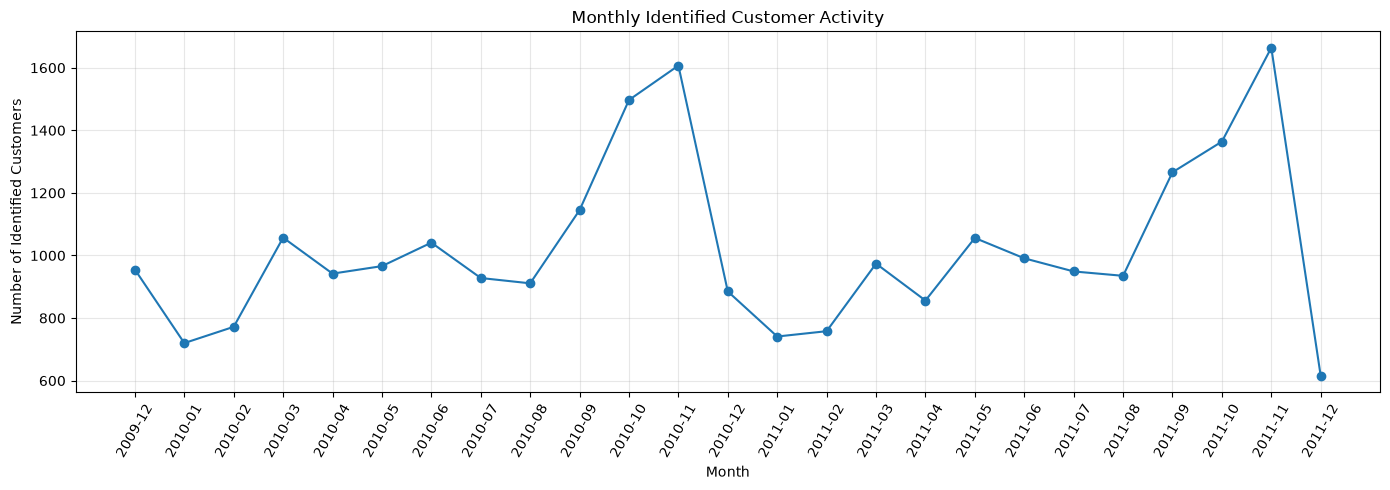

In [3]:
# Cell 3: Monthly transaction and customer activity

df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

monthly_activity = df.groupby("YearMonth").agg(
    Transactions=("Invoice", "nunique"),
    PurchaseRecords=("Invoice", "count"),
    IdentifiedCustomers=("Customer ID", "nunique"),
    Revenue=("TransactionValue", "sum")
).reset_index()

display(monthly_activity)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_activity["YearMonth"].astype(str),
    monthly_activity["IdentifiedCustomers"],
    marker="o"
)

plt.title("Monthly Identified Customer Activity")
plt.xlabel("Month")
plt.ylabel("Number of Identified Customers")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Check temporal coverage

print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())

print("\nMonthly activity table:")
display(monthly_activity)

print("\nNumber of months:", len(monthly_activity))
print("First month:", monthly_activity["YearMonth"].min())
print("Last month:", monthly_activity["YearMonth"].max())

Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00

Monthly activity table:


,YearMonth,Transactions,PurchaseRecords,IdentifiedCustomers,Revenue
0,2009-12,1682,43453,955,"822,483.95"
1,2010-01,1105,30317,720,"651,155.11"
2,2010-02,1201,27952,772,"551,504.73"
3,2010-03,1681,39841,1057,"830,915.26"
4,2010-04,1462,32858,942,"678,875.25"
5,2010-05,1500,33383,966,"657,705.50"
6,2010-06,1645,38391,1041,"749,537.31"
7,2010-07,1529,32112,928,"648,810.27"
8,2010-08,1425,32109,911,"695,251.91"
9,2010-09,1839,40630,1145,"921,696.99"



Number of months: 25
First month: 2009-12
Last month: 2011-12


In [5]:
# Cell 5: Define observation and prediction windows

OBSERVATION_MONTHS = 6
PREDICTION_MONTHS = 3

# Exclude incomplete December 2011
DATA_END = pd.Timestamp("2011-11-30 23:59:59")

# First observation period: Dec 2009 – May 2010
first_snapshot = pd.Timestamp("2010-05-31")

# Last snapshot: Aug 2011
last_snapshot = pd.Timestamp("2011-08-31")

snapshot_dates = pd.date_range(
    start=first_snapshot,
    end=last_snapshot,
    freq="ME"
)

print("Observation window:", OBSERVATION_MONTHS, "months")
print("Prediction window:", PREDICTION_MONTHS, "months")
print("Number of snapshots:", len(snapshot_dates))

print("\nEligible snapshots:")

for snapshot in snapshot_dates:
    observation_start = snapshot - pd.DateOffset(
        months=OBSERVATION_MONTHS
    ) + pd.Timedelta(days=1)

    prediction_end = snapshot + pd.DateOffset(
        months=PREDICTION_MONTHS
    )

    print(
        f"Observation: {observation_start.date()} to {snapshot.date()} | "
        f"Prediction ends: {prediction_end.date()}"
    )

assert all(
    snapshot + pd.DateOffset(months=PREDICTION_MONTHS) <= DATA_END
    for snapshot in snapshot_dates
)

print("\nAll prediction windows fit within complete data coverage.")

Observation window: 6 months
Prediction window: 3 months
Number of snapshots: 16

Eligible snapshots:
Observation: 2009-12-01 to 2010-05-31 | Prediction ends: 2010-08-31
Observation: 2009-12-31 to 2010-06-30 | Prediction ends: 2010-09-30
Observation: 2010-02-01 to 2010-07-31 | Prediction ends: 2010-10-31
Observation: 2010-03-01 to 2010-08-31 | Prediction ends: 2010-11-30
Observation: 2010-03-31 to 2010-09-30 | Prediction ends: 2010-12-30
Observation: 2010-05-01 to 2010-10-31 | Prediction ends: 2011-01-31
Observation: 2010-05-31 to 2010-11-30 | Prediction ends: 2011-02-28
Observation: 2010-07-01 to 2010-12-31 | Prediction ends: 2011-03-31
Observation: 2010-08-01 to 2011-01-31 | Prediction ends: 2011-04-30
Observation: 2010-08-29 to 2011-02-28 | Prediction ends: 2011-05-28
Observation: 2010-10-01 to 2011-03-31 | Prediction ends: 2011-06-30
Observation: 2010-10-31 to 2011-04-30 | Prediction ends: 2011-07-30
Observation: 2010-12-01 to 2011-05-31 | Prediction ends: 2011-08-31
Observation: 2

In [7]:
# Cell 5: Define exact calendar-month windows

OBSERVATION_MONTHS = 6
PREDICTION_MONTHS = 3

DATA_END = pd.Period("2011-11", freq="M").end_time

snapshot_dates = pd.date_range(
    start="2010-05-31",
    end="2011-08-31",
    freq="ME"
)

snapshot_windows = []

for snapshot in snapshot_dates:

    snapshot_month = snapshot.to_period("M")

    observation_start = (
        snapshot_month - (OBSERVATION_MONTHS - 1)
    ).start_time

    observation_end = snapshot_month.end_time

    prediction_start = (
        snapshot_month + 1
    ).start_time

    prediction_end = (
        snapshot_month + PREDICTION_MONTHS
    ).end_time

    snapshot_windows.append({
        "Observation Start": observation_start,
        "Observation End": observation_end,
        "Prediction Start": prediction_start,
        "Prediction End": prediction_end
    })

snapshot_windows_df = pd.DataFrame(snapshot_windows)

display(snapshot_windows_df)

assert len(snapshot_windows_df) == 16
assert snapshot_windows_df["Prediction End"].max() <= DATA_END

print("All 16 snapshot windows validated!")

,Observation Start,Observation End,Prediction Start,Prediction End
0,2009-12-01,2010-05-31 23:59:59.999999,2010-06-01,2010-08-31 23:59:59.999999
1,2010-01-01,2010-06-30 23:59:59.999999,2010-07-01,2010-09-30 23:59:59.999999
2,2010-02-01,2010-07-31 23:59:59.999999,2010-08-01,2010-10-31 23:59:59.999999
3,2010-03-01,2010-08-31 23:59:59.999999,2010-09-01,2010-11-30 23:59:59.999999
4,2010-04-01,2010-09-30 23:59:59.999999,2010-10-01,2010-12-31 23:59:59.999999
5,2010-05-01,2010-10-31 23:59:59.999999,2010-11-01,2011-01-31 23:59:59.999999
6,2010-06-01,2010-11-30 23:59:59.999999,2010-12-01,2011-02-28 23:59:59.999999
7,2010-07-01,2010-12-31 23:59:59.999999,2011-01-01,2011-03-31 23:59:59.999999
8,2010-08-01,2011-01-31 23:59:59.999999,2011-02-01,2011-04-30 23:59:59.999999
9,2010-09-01,2011-02-28 23:59:59.999999,2011-03-01,2011-05-31 23:59:59.999999


All 16 snapshot windows validated!


In [8]:
# Cell 6: Generate customer-level labels for each snapshot

customer_snapshots = []

for i, window in snapshot_windows_df.iterrows():

    observation_start = window["Observation Start"]
    observation_end = window["Observation End"]
    prediction_start = window["Prediction Start"]
    prediction_end = window["Prediction End"]

    # Customers who purchased during the observation period
    observation_data = df[
        (df["InvoiceDate"] >= observation_start) &
        (df["InvoiceDate"] <= observation_end) &
        (df["Customer ID"].notna())
    ]

    # Customers who purchased during the prediction period
    prediction_data = df[
        (df["InvoiceDate"] >= prediction_start) &
        (df["InvoiceDate"] <= prediction_end) &
        (df["Customer ID"].notna())
    ]

    observed_customers = observation_data["Customer ID"].unique()

    future_customers = set(
        prediction_data["Customer ID"].unique()
    )

    # Create one record for each observed customer
    snapshot_df = pd.DataFrame({
        "Customer ID": observed_customers
    })

    # 1 = no future purchase; 0 = at least one future purchase
    snapshot_df["Inactive"] = (
        ~snapshot_df["Customer ID"].isin(future_customers)
    ).astype(int)

    snapshot_df["Snapshot"] = observation_end

    customer_snapshots.append(snapshot_df)

# Combine all snapshots
labels_df = pd.concat(customer_snapshots, ignore_index=True)

print("Total customer-snapshot records:", len(labels_df))
print("Unique customers:", labels_df["Customer ID"].nunique())
print("Number of snapshots:", labels_df["Snapshot"].nunique())

print("\nSample records:")
display(labels_df.head(10))

Total customer-snapshot records: 48394
Unique customers: 5249
Number of snapshots: 16

Sample records:


,Customer ID,Inactive,Snapshot
0,"13,085.00",1,2010-05-31 23:59:59.999999
1,"13,078.00",0,2010-05-31 23:59:59.999999
2,"15,362.00",1,2010-05-31 23:59:59.999999
3,"18,102.00",0,2010-05-31 23:59:59.999999
4,"12,682.00",0,2010-05-31 23:59:59.999999
5,"18,087.00",0,2010-05-31 23:59:59.999999
6,"13,635.00",1,2010-05-31 23:59:59.999999
7,"14,110.00",0,2010-05-31 23:59:59.999999
8,"12,636.00",1,2010-05-31 23:59:59.999999
9,"17,519.00",0,2010-05-31 23:59:59.999999


,Count,Percentage
Active (0),23812,49.20
Inactive (1),24582,50.80


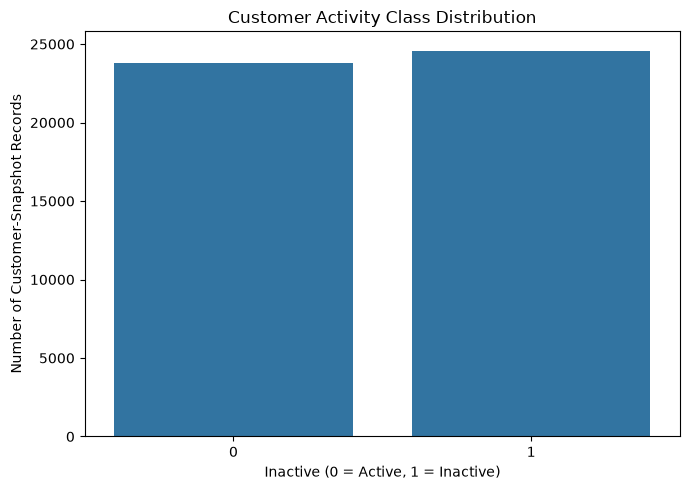

In [9]:
# Cell 7: Overall class distribution

class_counts = labels_df["Inactive"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(labels_df) * 100
})

class_distribution.index = ["Active (0)", "Inactive (1)"]

display(class_distribution)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=labels_df,
    x="Inactive"
)

plt.title("Customer Activity Class Distribution")
plt.xlabel("Inactive (0 = Active, 1 = Inactive)")
plt.ylabel("Number of Customer-Snapshot Records")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "inactivity_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,Snapshot,Total_Customers,Inactive_Customers,Active_Customers,Inactivity_Rate
0,2010-05-31 23:59:59.999999,2703,1359,1344,50.28
1,2010-06-30 23:59:59.999999,2757,1338,1419,48.53
2,2010-07-31 23:59:59.999999,2832,1204,1628,42.51
3,2010-08-31 23:59:59.999999,2868,1089,1779,37.97
4,2010-09-30 23:59:59.999999,2924,1236,1688,42.27
5,2010-10-31 23:59:59.999999,3222,1632,1590,50.65
6,2010-11-30 23:59:59.999999,3497,2173,1324,62.14
7,2010-12-31 23:59:59.999999,3428,2140,1288,62.43
8,2011-01-31 23:59:59.999999,3386,2053,1333,60.63
9,2011-02-28 23:59:59.999999,3358,1933,1425,57.56


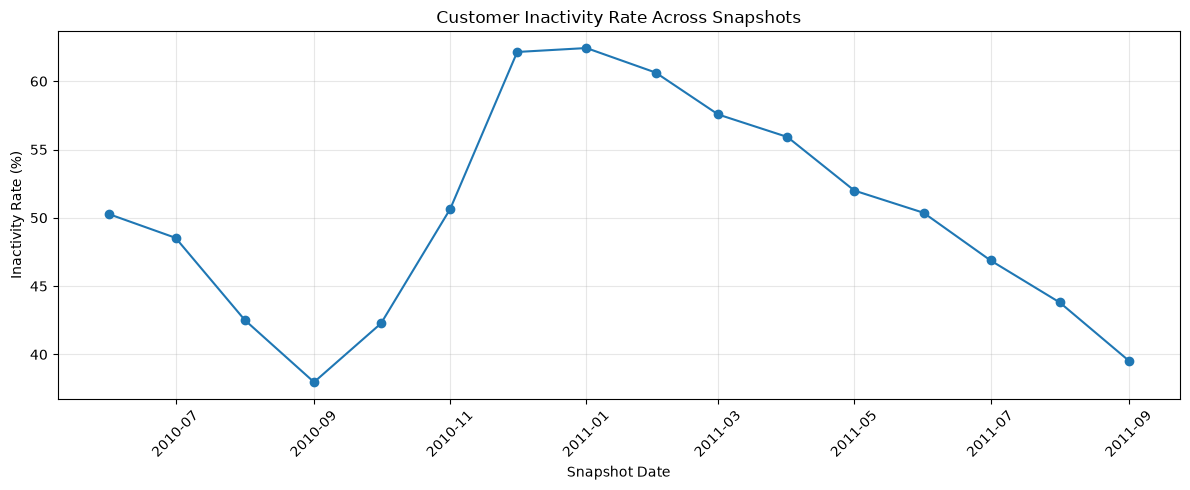

In [10]:
# Cell 8: Inactivity rate across snapshots

snapshot_distribution = labels_df.groupby("Snapshot").agg(
    Total_Customers=("Customer ID", "count"),
    Inactive_Customers=("Inactive", "sum")
).reset_index()

snapshot_distribution["Active_Customers"] = (
    snapshot_distribution["Total_Customers"] -
    snapshot_distribution["Inactive_Customers"]
)

snapshot_distribution["Inactivity_Rate"] = (
    snapshot_distribution["Inactive_Customers"] /
    snapshot_distribution["Total_Customers"] * 100
)

display(snapshot_distribution)

plt.figure(figsize=(12, 5))

plt.plot(
    snapshot_distribution["Snapshot"],
    snapshot_distribution["Inactivity_Rate"],
    marker="o"
)

plt.title("Customer Inactivity Rate Across Snapshots")
plt.xlabel("Snapshot Date")
plt.ylabel("Inactivity Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "inactivity_rate_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Cell 9: Feature engineering for each customer snapshot

feature_snapshots = []

for i, window in snapshot_windows_df.iterrows():

    observation_start = window["Observation Start"]
    observation_end = window["Observation End"]

    # Use ONLY observation-period transactions
    observation_data = df[
        (df["InvoiceDate"] >= observation_start) &
        (df["InvoiceDate"] <= observation_end) &
        (df["Customer ID"].notna())
    ].copy()

    # Invoice-level spending for average order value
    invoice_values = (
        observation_data.groupby(
            ["Customer ID", "Invoice"]
        )["TransactionValue"]
        .sum()
        .reset_index()
    )

    avg_order_value = (
        invoice_values.groupby("Customer ID")["TransactionValue"]
        .mean()
        .rename("AverageOrderValue")
    )

    # Customer-level behavioural features
    customer_features = observation_data.groupby("Customer ID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("TransactionValue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        ActiveMonths=("InvoiceDate",
                      lambda x: x.dt.to_period("M").nunique())
    )

    customer_features["Recency"] = (
        observation_end.normalize() -
        customer_features["LastPurchase"].dt.normalize()
    ).dt.days

    customer_features = customer_features.join(avg_order_value)

    customer_features = customer_features.drop(
        columns=["LastPurchase"]
    )

    customer_features = customer_features.reset_index()

    customer_features["Snapshot"] = observation_end

    feature_snapshots.append(customer_features)

# Combine all feature snapshots
features_df = pd.concat(
    feature_snapshots,
    ignore_index=True
)

print("Feature dataset shape:", features_df.shape)
print("\nFeatures:")
print(features_df.columns.tolist())

display(features_df.head())

Feature dataset shape: (48394, 9)

Features:
['Customer ID', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'ActiveMonths', 'Recency', 'AverageOrderValue', 'Snapshot']


,Customer ID,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveMonths,Recency,AverageOrderValue,Snapshot
0,"12,346.00",10,230.55,51,7,3,90,23.05,2010-05-31 23:59:59.999999
1,"12,349.00",2,"1,268.52",474,47,2,13,634.26,2010-05-31 23:59:59.999999
2,"12,355.00",1,488.21,303,22,1,10,488.21,2010-05-31 23:59:59.999999
3,"12,358.00",1,"1,429.83",309,17,1,174,"1,429.83",2010-05-31 23:59:59.999999
4,"12,359.00",4,"1,522.23",777,65,2,69,380.56,2010-05-31 23:59:59.999999


In [12]:
# Cell 10: Merge customer features with inactivity labels

modeling_df = pd.merge(
    features_df,
    labels_df,
    on=["Customer ID", "Snapshot"],
    how="inner",
    validate="one_to_one"
)

# Remove duplicate Snapshot column created by the merge
# (merge already retains one shared Snapshot column)

print("Modeling dataset shape:", modeling_df.shape)

print("\nTarget distribution:")
display(modeling_df["Inactive"].value_counts())

print("\nMissing values:")
display(modeling_df.isnull().sum())

print("\nDuplicate customer-snapshot records:",
      modeling_df.duplicated(
          subset=["Customer ID", "Snapshot"]
      ).sum())

display(modeling_df.head())

Modeling dataset shape: (48394, 10)

Target distribution:


Inactive
1    24582
0    23812
Name: count, dtype: int64


Missing values:


Customer ID          0
Frequency            0
Monetary             0
TotalQuantity        0
UniqueProducts       0
ActiveMonths         0
Recency              0
AverageOrderValue    0
Snapshot             0
Inactive             0
dtype: int64


Duplicate customer-snapshot records: 0


,Customer ID,Frequency,Monetary,TotalQuantity,UniqueProducts,ActiveMonths,Recency,AverageOrderValue,Snapshot,Inactive
0,"12,346.00",10,230.55,51,7,3,90,23.05,2010-05-31 23:59:59.999999,0
1,"12,349.00",2,"1,268.52",474,47,2,13,634.26,2010-05-31 23:59:59.999999,1
2,"12,355.00",1,488.21,303,22,1,10,488.21,2010-05-31 23:59:59.999999,1
3,"12,358.00",1,"1,429.83",309,17,1,174,"1,429.83",2010-05-31 23:59:59.999999,0
4,"12,359.00",4,"1,522.23",777,65,2,69,380.56,2010-05-31 23:59:59.999999,0


,count,mean,std,min,25%,50%,75%,max
Recency,"48,394.00",65.48,51.26,0.00,21.00,53.00,104.00,183.00
Frequency,"48,394.00",2.89,4.42,1.00,1.00,2.00,3.00,126.00
Monetary,"48,394.00","1,316.91","4,731.71",1.30,264.15,524.65,"1,143.60","179,248.38"
AverageOrderValue,"48,394.00",398.39,999.92,1.30,177.80,294.76,435.65,"77,183.60"
TotalQuantity,"48,394.00",806.50,"3,618.45",1.00,129.00,289.00,661.00,"220,600.00"
UniqueProducts,"48,394.00",45.61,58.98,1.00,14.00,29.00,57.00,"1,278.00"
ActiveMonths,"48,394.00",2.00,1.33,1.00,1.00,1.00,3.00,6.00



Feature skewness:


AverageOrderValue   57.92
TotalQuantity       23.88
Monetary            18.01
Frequency            9.36
UniqueProducts       6.23
ActiveMonths         1.40
Recency              0.60
dtype: float64

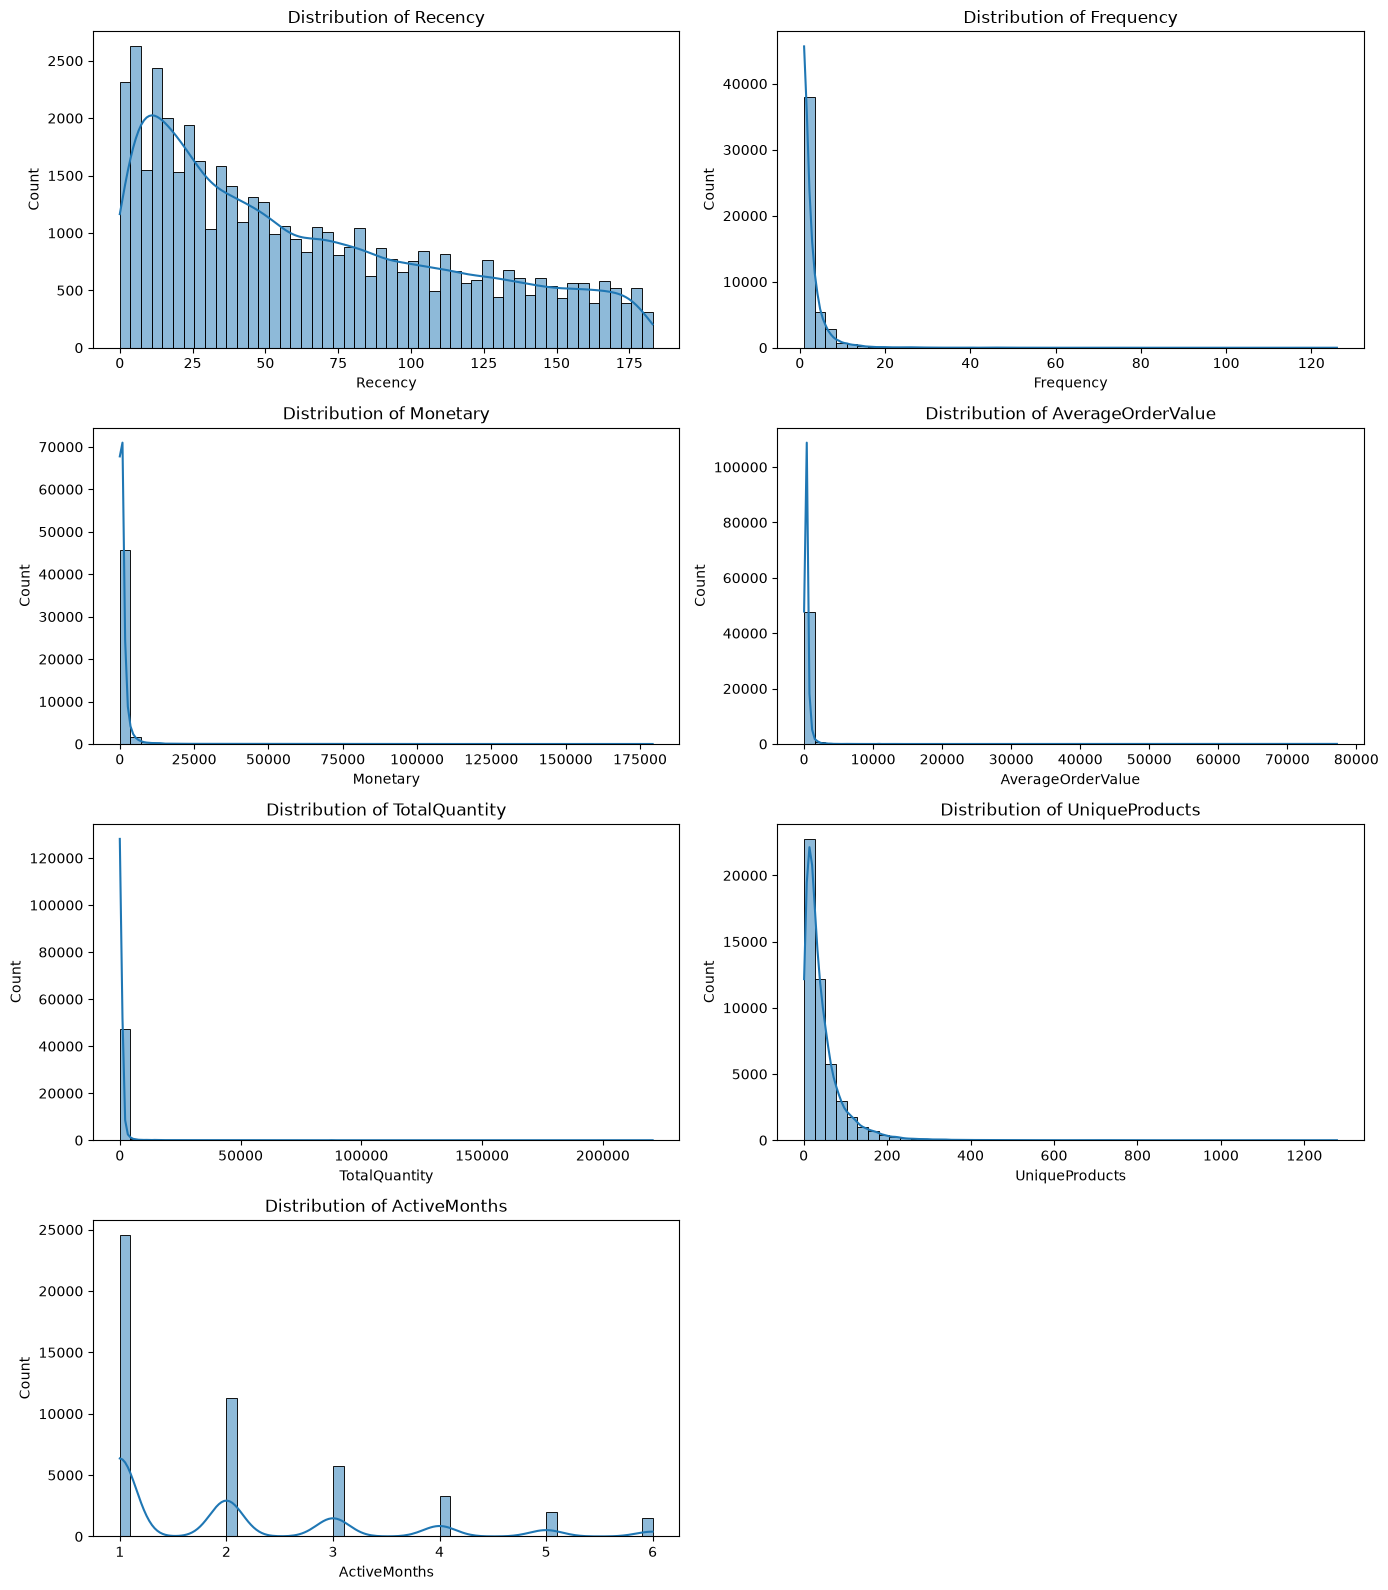

In [13]:
# Cell 11: Feature distribution analysis

feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveMonths"
]

# Summary statistics
display(modeling_df[feature_columns].describe().T)

# Skewness
skewness = modeling_df[feature_columns].skew()

print("\nFeature skewness:")
display(skewness.sort_values(ascending=False))

# Distribution plots
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, column in enumerate(feature_columns):
    sns.histplot(
        modeling_df[column],
        bins=50,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")

# Hide unused subplot
axes[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "feature_distributions_before_transformation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Cell 12: Create chronological train-validation-test splits

train_end = pd.Timestamp("2010-10-31")
validation_start = pd.Timestamp("2011-02-28")
validation_end = pd.Timestamp("2011-04-30")
test_snapshot = pd.Timestamp("2011-08-31")

# Select records using snapshot dates
train_df = modeling_df[
    modeling_df["Snapshot"].dt.normalize() <= train_end
].copy()

validation_df = modeling_df[
    (modeling_df["Snapshot"].dt.normalize() >= validation_start) &
    (modeling_df["Snapshot"].dt.normalize() <= validation_end)
].copy()

test_df = modeling_df[
    modeling_df["Snapshot"].dt.normalize() == test_snapshot
].copy()

# Verify label maturity
train_label_end = (
    train_df["Snapshot"].max() + pd.DateOffset(months=3)
)

validation_label_end = (
    validation_df["Snapshot"].max() + pd.DateOffset(months=3)
)

print("TRAINING")
print("Records:", len(train_df))
print("Snapshot range:",
      train_df["Snapshot"].min(),
      "to",
      train_df["Snapshot"].max())
print("Latest label maturity:", train_label_end)

print("\nVALIDATION")
print("Records:", len(validation_df))
print("Snapshot range:",
      validation_df["Snapshot"].min(),
      "to",
      validation_df["Snapshot"].max())
print("Latest label maturity:", validation_label_end)

print("\nFINAL TEST")
print("Records:", len(test_df))
print("Snapshot:", test_df["Snapshot"].unique())

# Temporal validation
assert train_label_end <= validation_df["Snapshot"].min()
assert validation_label_end <= test_df["Snapshot"].min()

assert len(train_df) > 0
assert len(validation_df) > 0
assert len(test_df) > 0

print("\nAll chronological split checks passed!")

TRAINING
Records: 17306
Snapshot range: 2010-05-31 23:59:59.999999 to 2010-10-31 23:59:59.999999
Latest label maturity: 2011-01-31 23:59:59.999999

VALIDATION
Records: 9739
Snapshot range: 2011-02-28 23:59:59.999999 to 2011-04-30 23:59:59.999999
Latest label maturity: 2011-07-30 23:59:59.999999

FINAL TEST
Records: 2813
Snapshot: <DatetimeArray>
['2011-08-31 23:59:59.999999']
Length: 1, dtype: datetime64[us]

All chronological split checks passed!


In [15]:
# Cell 13: Class distribution across chronological splits

def inspect_split(data, split_name):
    counts = data["Inactive"].value_counts().sort_index()

    result = pd.DataFrame({
        "Class": ["Active (0)", "Inactive (1)"],
        "Count": [
            counts.get(0, 0),
            counts.get(1, 0)
        ],
        "Percentage": [
            counts.get(0, 0) / len(data) * 100,
            counts.get(1, 0) / len(data) * 100
        ]
    })

    result.insert(0, "Dataset", split_name)
    return result


split_distribution = pd.concat([
    inspect_split(train_df, "Training"),
    inspect_split(validation_df, "Validation"),
    inspect_split(test_df, "Test")
], ignore_index=True)

display(split_distribution.round(2))

,Dataset,Class,Count,Percentage
0,Training,Active (0),9448,54.59
1,Training,Inactive (1),7858,45.41
2,Validation,Active (0),4358,44.75
3,Validation,Inactive (1),5381,55.25
4,Test,Active (0),1701,60.47
5,Test,Inactive (1),1112,39.53


In [16]:
# Cell 14: Separate predictors and target

X_train = train_df[feature_columns].copy()
y_train = train_df["Inactive"].copy()

X_validation = validation_df[feature_columns].copy()
y_validation = validation_df["Inactive"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["Inactive"].copy()

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nTraining feature columns:")
print(X_train.columns.tolist())

assert list(X_train.columns) == feature_columns
assert list(X_validation.columns) == feature_columns
assert list(X_test.columns) == feature_columns

assert "Customer ID" not in X_train.columns
assert "Snapshot" not in X_train.columns
assert "Inactive" not in X_train.columns

print("\nModel inputs prepared successfully!")

Training: (17306, 7) (17306,)
Validation: (9739, 7) (9739,)
Test: (2813, 7) (2813,)

Training feature columns:
['Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'TotalQuantity', 'UniqueProducts', 'ActiveMonths']

Model inputs prepared successfully!


In [17]:
# Cell 15: Logistic Regression pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression

log_features = [
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts"
]

# Transform selected columns while retaining all other features
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "log_transform",
            FunctionTransformer(np.log1p, validate=False),
            log_features
        )
    ],
    remainder="passthrough"
)

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")

Logistic Regression pipeline created successfully!


In [18]:
# Cell 16: Train Logistic Regression

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed!")

print("\nTraining accuracy:",
      logistic_pipeline.score(X_train, y_train))

print("Validation accuracy:",
      logistic_pipeline.score(X_validation, y_validation))

Logistic Regression training completed!

Training accuracy: 0.6704611117531492
Validation accuracy: 0.6765581681897526


LOGISTIC REGRESSION — VALIDATION RESULTS

Accuracy: 0.6766
Precision: 0.7161
Recall: 0.6869
F1-score: 0.7012
ROC-AUC: 0.7421
PR-AUC: 0.7370

Classification Report:

              precision    recall  f1-score   support

      Active       0.63      0.66      0.65      4358
    Inactive       0.72      0.69      0.70      5381

    accuracy                           0.68      9739
   macro avg       0.67      0.68      0.67      9739
weighted avg       0.68      0.68      0.68      9739



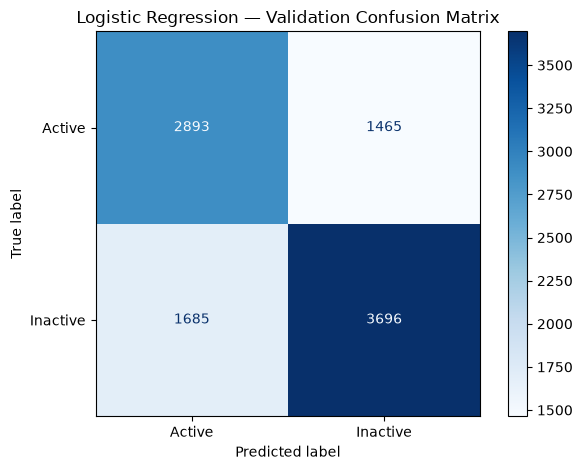

In [19]:
# Cell 17: Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict classes and probabilities
y_val_pred = logistic_pipeline.predict(X_validation)

y_val_proba = logistic_pipeline.predict_proba(
    X_validation
)[:, 1]

# Calculate evaluation metrics
metrics = {
    "Accuracy": accuracy_score(y_validation, y_val_pred),
    "Precision": precision_score(y_validation, y_val_pred),
    "Recall": recall_score(y_validation, y_val_pred),
    "F1-score": f1_score(y_validation, y_val_pred),
    "ROC-AUC": roc_auc_score(y_validation, y_val_proba),
    "PR-AUC": average_precision_score(y_validation, y_val_proba)
}

print("LOGISTIC REGRESSION — VALIDATION RESULTS\n")

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_validation,
    y_val_pred,
    target_names=["Active", "Inactive"]
))

# Confusion matrix
cm = confusion_matrix(y_validation, y_val_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Active", "Inactive"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Cell 18: Train Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

print("Training accuracy:",
      rf_model.score(X_train, y_train))

print("Validation accuracy:",
      rf_model.score(X_validation, y_validation))

Random Forest training completed!
Training accuracy: 0.9056396625447821
Validation accuracy: 0.6449327446349727


In [21]:
# Cell 19: Evaluate Random Forest

rf_val_pred = rf_model.predict(X_validation)

rf_val_proba = rf_model.predict_proba(
    X_validation
)[:, 1]

rf_metrics = {
    "Accuracy": accuracy_score(y_validation, rf_val_pred),
    "Precision": precision_score(y_validation, rf_val_pred),
    "Recall": recall_score(y_validation, rf_val_pred),
    "F1-score": f1_score(y_validation, rf_val_pred),
    "ROC-AUC": roc_auc_score(y_validation, rf_val_proba),
    "PR-AUC": average_precision_score(y_validation, rf_val_proba)
}

print("RANDOM FOREST — VALIDATION RESULTS\n")

for metric, value in rf_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_validation,
    rf_val_pred,
    target_names=["Active", "Inactive"]
))

RANDOM FOREST — VALIDATION RESULTS

Accuracy: 0.6449
Precision: 0.7174
Recall: 0.5897
F1-score: 0.6473
ROC-AUC: 0.7244
PR-AUC: 0.7248

Classification Report:

              precision    recall  f1-score   support

      Active       0.58      0.71      0.64      4358
    Inactive       0.72      0.59      0.65      5381

    accuracy                           0.64      9739
   macro avg       0.65      0.65      0.64      9739
weighted avg       0.66      0.64      0.65      9739



In [22]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

print("Training accuracy:", gb_model.score(X_train, y_train))
print("Validation accuracy:", gb_model.score(X_validation, y_validation))

Gradient Boosting training completed!
Training accuracy: 0.6798798104703571
Validation accuracy: 0.6714241708594312


In [23]:
gb_val_pred = gb_model.predict(X_validation)

gb_val_proba = gb_model.predict_proba(X_validation)[:, 1]

gb_metrics = {
    "Accuracy": accuracy_score(y_validation, gb_val_pred),
    "Precision": precision_score(y_validation, gb_val_pred),
    "Recall": recall_score(y_validation, gb_val_pred),
    "F1-score": f1_score(y_validation, gb_val_pred),
    "ROC-AUC": roc_auc_score(y_validation, gb_val_proba),
    "PR-AUC": average_precision_score(y_validation, gb_val_proba)
}

print("GRADIENT BOOSTING — VALIDATION RESULTS\n")

for metric, value in gb_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_validation,
    gb_val_pred,
    target_names=["Active", "Inactive"]
))

GRADIENT BOOSTING — VALIDATION RESULTS

Accuracy: 0.6714
Precision: 0.7196
Recall: 0.6640
F1-score: 0.6907
ROC-AUC: 0.7450
PR-AUC: 0.7423

Classification Report:

              precision    recall  f1-score   support

      Active       0.62      0.68      0.65      4358
    Inactive       0.72      0.66      0.69      5381

    accuracy                           0.67      9739
   macro avg       0.67      0.67      0.67      9739
weighted avg       0.68      0.67      0.67      9739



,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Logistic Regression,0.68,0.72,0.69,0.70,0.74,0.74
Random Forest,0.64,0.72,0.59,0.65,0.72,0.72
Gradient Boosting,0.67,0.72,0.66,0.69,0.74,0.74


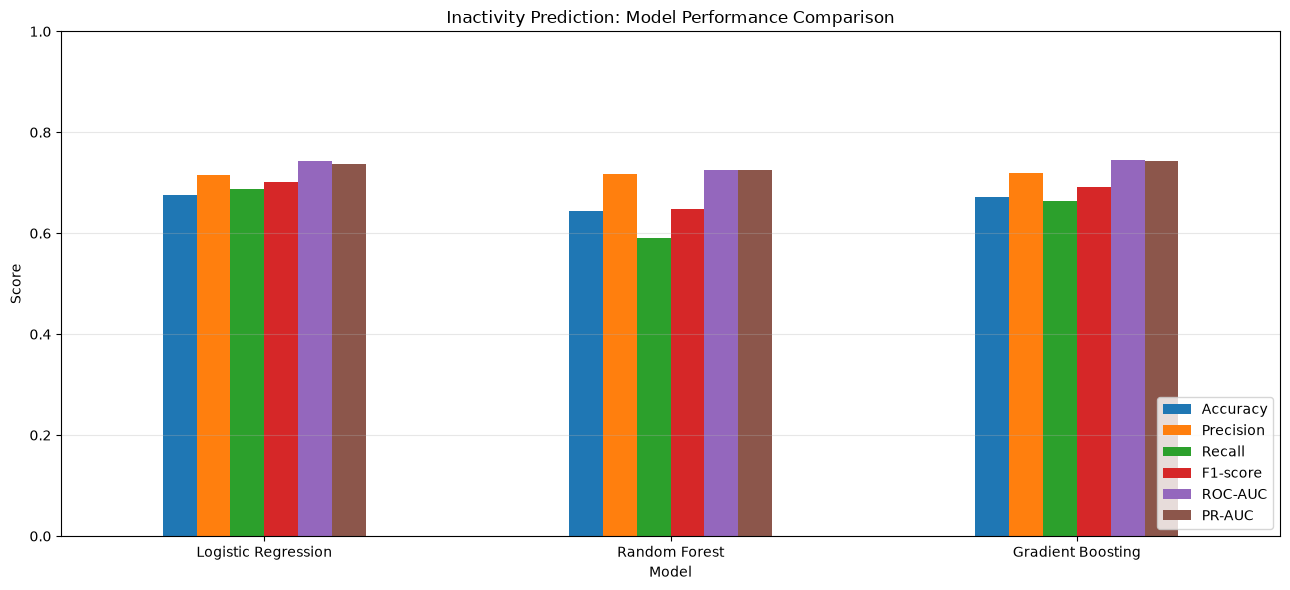

In [24]:
# Cell 22: Compare all three models

results = pd.DataFrame({
    "Logistic Regression": metrics,
    "Random Forest": rf_metrics,
    "Gradient Boosting": gb_metrics
}).T

display(results.round(4))

# Visual comparison
results[["Accuracy", "Precision", "Recall", "F1-score",
         "ROC-AUC", "PR-AUC"]].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Inactivity Prediction: Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# Cell 23: Threshold analysis

from sklearn.metrics import precision_recall_curve

models_probabilities = {
    "Logistic Regression": logistic_pipeline.predict_proba(
        X_validation
    )[:, 1],

    "Gradient Boosting": gb_model.predict_proba(
        X_validation
    )[:, 1]
}

threshold_results = []

thresholds_to_test = [
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65, 0.70
]

for model_name, probabilities in models_probabilities.items():

    for threshold in thresholds_to_test:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_validation, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_validation, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_validation, predictions, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Model,Threshold,Precision,Recall,F1-score
0,Logistic Regression,0.30,0.66,0.91,0.77
1,Logistic Regression,0.35,0.67,0.89,0.76
2,Logistic Regression,0.40,0.69,0.83,0.75
3,Logistic Regression,0.45,0.71,0.75,0.73
4,Logistic Regression,0.50,0.72,0.69,0.70
5,Logistic Regression,0.55,0.73,0.62,0.67
6,Logistic Regression,0.60,0.75,0.47,0.58
7,Logistic Regression,0.65,0.77,0.24,0.37
8,Logistic Regression,0.70,0.79,0.09,0.17
9,Gradient Boosting,0.30,0.66,0.92,0.77


In [26]:
# Cell 24: Compare customer targeting at different thresholds

business_thresholds = [0.30, 0.40, 0.50]

impact_results = []

for model_name, probabilities in models_probabilities.items():

    for threshold in business_thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_validation, predictions
        ).ravel()

        impact_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Customers_Flagged": int(tp + fp),
            "Actually_Inactive_Flagged": int(tp),
            "Active_Customers_Flagged": int(fp),
            "Inactive_Customers_Missed": int(fn),
            "Percentage_Flagged": (tp + fp) / len(y_validation) * 100
        })

impact_df = pd.DataFrame(impact_results)

display(impact_df.round(2))

,Model,Threshold,Customers_Flagged,Actually_Inactive_Flagged,Active_Customers_Flagged,Inactive_Customers_Missed,Percentage_Flagged
0,Logistic Regression,0.30,7473,4918,2555,463,76.73
1,Logistic Regression,0.40,6441,4456,1985,925,66.14
2,Logistic Regression,0.50,5161,3696,1465,1685,52.99
3,Gradient Boosting,0.30,7508,4936,2572,445,77.09
4,Gradient Boosting,0.40,6419,4456,1963,925,65.91
5,Gradient Boosting,0.50,4965,3573,1392,1808,50.98


In [27]:
# Cell 25: Capacity-based customer targeting

campaign_capacities = [0.30, 0.40, 0.50]

capacity_results = []

for model_name, probabilities in models_probabilities.items():

    for capacity in campaign_capacities:

        # Number of customers the retailer can target
        n_target = int(np.ceil(len(y_validation) * capacity))

        # Select customers with the highest predicted risk
        ranked_indices = np.argsort(probabilities)[::-1]
        selected_indices = ranked_indices[:n_target]

        targeted_predictions = np.zeros(len(y_validation), dtype=int)
        targeted_predictions[selected_indices] = 1

        tn, fp, fn, tp = confusion_matrix(
            y_validation,
            targeted_predictions
        ).ravel()

        capacity_results.append({
            "Model": model_name,
            "Campaign_Capacity": capacity * 100,
            "Customers_Targeted": n_target,
            "Inactive_Customers_Caught": tp,
            "Active_Customers_Flagged": fp,
            "Recall": recall_score(
                y_validation, targeted_predictions
            ),
            "Precision": precision_score(
                y_validation, targeted_predictions
            )
        })

capacity_df = pd.DataFrame(capacity_results)

display(capacity_df.round(4))

,Model,Campaign_Capacity,Customers_Targeted,Inactive_Customers_Caught,Active_Customers_Flagged,Recall,Precision
0,Logistic Regression,30.00,2922,2223,699,0.41,0.76
1,Logistic Regression,40.00,3896,2894,1002,0.54,0.74
2,Logistic Regression,50.00,4870,3522,1348,0.65,0.72
3,Gradient Boosting,30.00,2922,2226,696,0.41,0.76
4,Gradient Boosting,40.00,3896,2885,1011,0.54,0.74
5,Gradient Boosting,50.00,4870,3506,1364,0.65,0.72


In [28]:
# Cell 26: Permutation Feature Importance

from sklearn.inspection import permutation_importance

# Logistic Regression
lr_importance = permutation_importance(
    logistic_pipeline,
    X_validation,
    y_validation,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Gradient Boosting
gb_importance = permutation_importance(
    gb_model,
    X_validation,
    y_validation,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Combine results
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Logistic_Regression": lr_importance.importances_mean,
    "LR_Std": lr_importance.importances_std,
    "Gradient_Boosting": gb_importance.importances_mean,
    "GB_Std": gb_importance.importances_std
})

importance_df = importance_df.sort_values(
    "Gradient_Boosting",
    ascending=False
)

display(importance_df.round(5))

,Feature,Logistic_Regression,LR_Std,Gradient_Boosting,GB_Std
6,ActiveMonths,0.13,0.01,0.09,0.01
2,Monetary,0.00,0.00,0.01,0.00
0,Recency,0.00,0.00,0.01,0.00
5,UniqueProducts,0.01,0.00,0.01,0.00
4,TotalQuantity,0.00,0.00,0.00,0.00
3,AverageOrderValue,0.00,0.00,0.00,0.00
1,Frequency,0.00,0.00,-0.00,0.00


In [29]:
# Cell 27: Compare feature distributions by target

validation_profiles = validation_df.groupby("Inactive")[
    feature_columns
].agg(["mean", "median", "std"])

display(validation_profiles.round(2))

Recency              Frequency             Monetary                  \
            mean median   std      mean median  std     mean median      std   
Inactive                                                                       
0          59.77  41.00 51.33      4.19   3.00 5.94 2,100.20 889.39 6,173.77   
1          97.35 106.00 53.90      1.75   1.00 1.75   678.75 360.85 2,187.15   

         AverageOrderValue                 TotalQuantity                  \
                      mean median      std          mean median      std   
Inactive                                                                   
0                   434.84 321.37   522.54      1,206.06 486.00 3,784.47   
1                   399.93 262.40 1,871.96        413.19 199.00 2,240.42   

         UniqueProducts              ActiveMonths              
                   mean median   std         mean median  std  
Inactive                                                       
0                 63.15  43.00 75.89         2.55   2.00 1.55  
1                 32.91  22.00 35.20         1.45   1.00 0.77

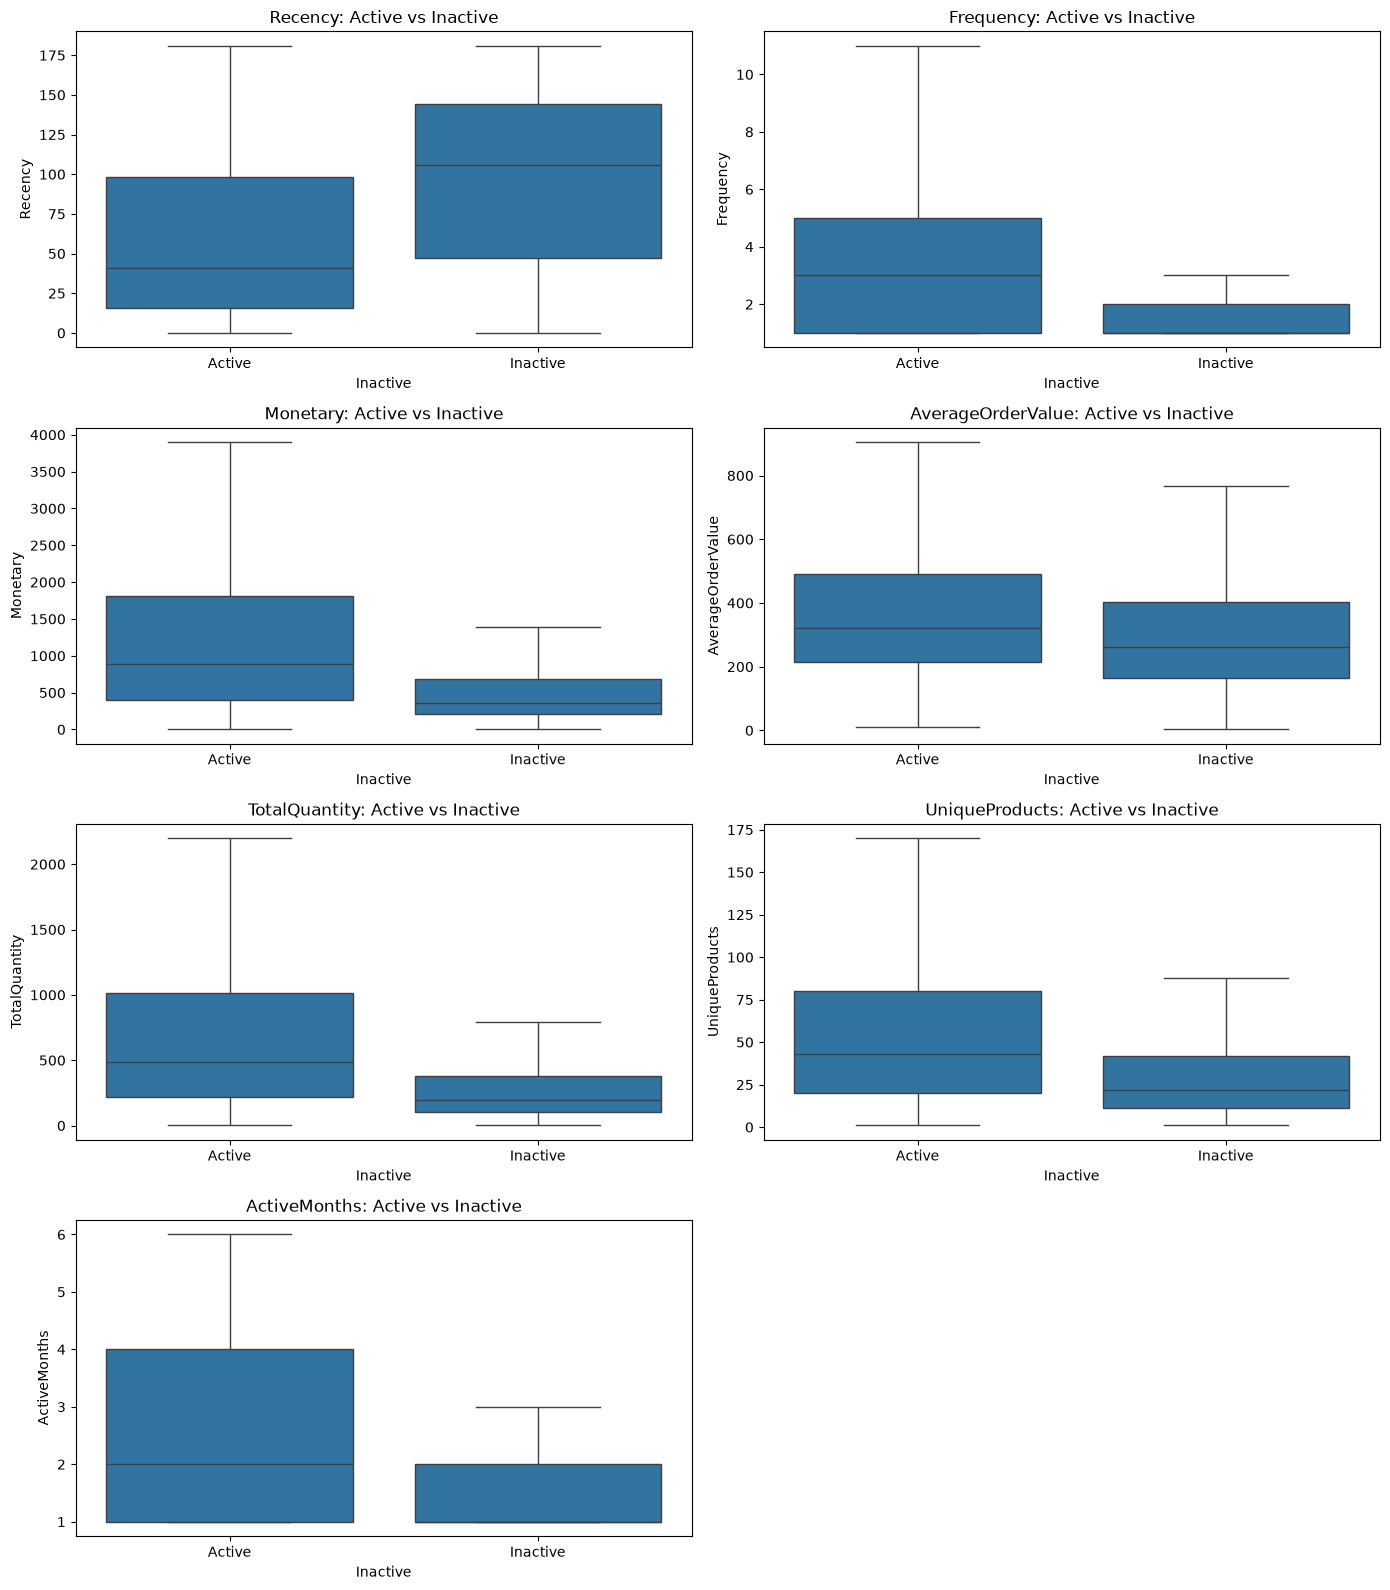

In [30]:
# Cell 28: Compare active and inactive customer behaviour

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, column in enumerate(feature_columns):

    sns.boxplot(
        data=validation_df,
        x="Inactive",
        y=column,
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(f"{column}: Active vs Inactive")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Active", "Inactive"])

axes[-1].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "customer_behaviour_by_inactivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# Cell 29: Investigate purchase intervals

interval_records = []

for i, window in snapshot_windows_df.iterrows():

    observation_start = window["Observation Start"]
    observation_end = window["Observation End"]

    observation_data = df[
        (df["InvoiceDate"] >= observation_start) &
        (df["InvoiceDate"] <= observation_end) &
        (df["Customer ID"].notna())
    ]

    # One timestamp per customer invoice
    invoice_dates = (
        observation_data[
            ["Customer ID", "Invoice", "InvoiceDate"]
        ]
        .drop_duplicates(["Customer ID", "Invoice"])
        .sort_values(["Customer ID", "InvoiceDate"])
    )

    # Calculate gaps between consecutive invoices
    invoice_dates["PurchaseGap"] = (
        invoice_dates.groupby("Customer ID")["InvoiceDate"]
        .diff()
        .dt.total_seconds() / 86400
    )

    interval_features = invoice_dates.groupby("Customer ID").agg(
        MeanPurchaseInterval=("PurchaseGap", "mean"),
        MedianPurchaseInterval=("PurchaseGap", "median"),
        PurchaseIntervalStd=("PurchaseGap", "std")
    ).reset_index()

    interval_features["Snapshot"] = observation_end

    interval_records.append(interval_features)

interval_features_df = pd.concat(
    interval_records,
    ignore_index=True
)

display(interval_features_df.head(10))

print("Interval dataset shape:", interval_features_df.shape)

print("\nSummary statistics:")
display(
    interval_features_df[
        [
            "MeanPurchaseInterval",
            "MedianPurchaseInterval",
            "PurchaseIntervalStd"
        ]
    ].describe().round(2)
)

,Customer ID,MeanPurchaseInterval,MedianPurchaseInterval,PurchaseIntervalStd,Snapshot
0,"12,346.00",8.69,3.99,12.80,2010-05-31 23:59:59.999999
1,"12,349.00",18.86,18.86,NaN,2010-05-31 23:59:59.999999
2,"12,355.00",NaN,NaN,NaN,2010-05-31 23:59:59.999999
3,"12,358.00",NaN,NaN,NaN,2010-05-31 23:59:59.999999
4,"12,359.00",35.94,14.94,39.75,2010-05-31 23:59:59.999999
5,"12,360.00",46.01,46.01,22.57,2010-05-31 23:59:59.999999
6,"12,361.00",103.04,103.04,NaN,2010-05-31 23:59:59.999999
7,"12,362.00",NaN,NaN,NaN,2010-05-31 23:59:59.999999
8,"12,366.00",NaN,NaN,NaN,2010-05-31 23:59:59.999999
9,"12,368.00",NaN,NaN,NaN,2010-05-31 23:59:59.999999


Interval dataset shape: (48394, 5)

Summary statistics:


,MeanPurchaseInterval,MedianPurchaseInterval,PurchaseIntervalStd
count,"26,550.00","26,550.00","16,185.00"
mean,42.09,40.65,23.12
std,33.22,34.23,18.63
min,0.00,0.00,0.00
25%,18.75,15.03,10.47
50%,34.01,32.01,18.02
75%,56.37,57.02,30.20
max,179.26,179.26,123.85


In [32]:
# Cell 30: Compare purchase intervals by activity outcome

interval_analysis = pd.merge(
    interval_features_df,
    labels_df[["Customer ID", "Snapshot", "Inactive"]],
    on=["Customer ID", "Snapshot"],
    how="inner",
    validate="one_to_one"
)

interval_columns = [
    "MeanPurchaseInterval",
    "MedianPurchaseInterval",
    "PurchaseIntervalStd"
]

# Compare missing-value percentages
missing_comparison = interval_analysis.groupby(
    "Inactive"
)[interval_columns].apply(
    lambda x: x.isna().mean() * 100
)

print("Missing values by customer outcome (%)")
display(missing_comparison.round(2))

# Compare available interval statistics
print("\nInterval statistics by customer outcome")

interval_profiles = interval_analysis.groupby(
    "Inactive"
)[interval_columns].agg(
    ["count", "mean", "median", "std"]
)

display(interval_profiles.round(2))

Missing values by customer outcome (%)


,MeanPurchaseInterval,MedianPurchaseInterval,PurchaseIntervalStd
Inactive,,,
0,28.89,28.89,49.63
1,60.87,60.87,82.95



Interval statistics by customer outcome


MeanPurchaseInterval                    MedianPurchaseInterval        \
                        count  mean median   std                  count  mean   
Inactive                                                                        
0                       16932 40.07  32.64 30.13                  16932 38.42   
1                        9618 45.64  37.08 37.79                   9618 44.57   

                      PurchaseIntervalStd                     
         median   std               count  mean median   std  
Inactive                                                      
0         30.85 31.31               11993 21.73  17.32 16.81  
1         35.93 38.53                4192 27.11  21.09 22.60

,Frequency,MeanPurchaseInterval,MedianPurchaseInterval,PurchaseIntervalStd
Frequency,1.00,-0.41,-0.45,-0.23
MeanPurchaseInterval,-0.41,1.00,0.97,0.52
MedianPurchaseInterval,-0.45,0.97,1.00,0.35
PurchaseIntervalStd,-0.23,0.52,0.35,1.00


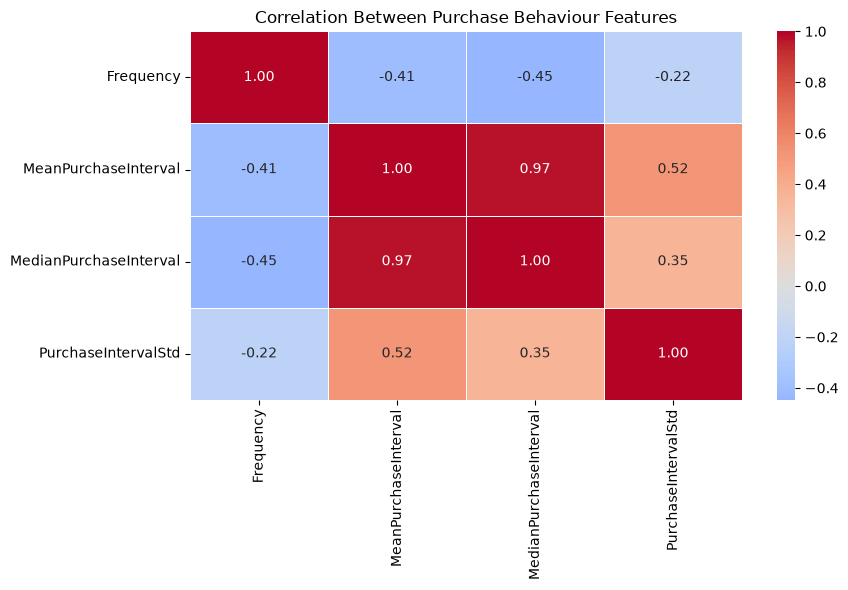

In [34]:
# Cell 31: Correlation between purchase interval features

# Retrieve Frequency from the original feature dataset
frequency_data = features_df[
    ["Customer ID", "Snapshot", "Frequency"]
]

# Merge using customer and snapshot identifiers
interval_correlation_data = interval_analysis.merge(
    frequency_data,
    on=["Customer ID", "Snapshot"],
    how="left",
    validate="one_to_one"
)

correlation_columns = [
    "Frequency",
    "MeanPurchaseInterval",
    "MedianPurchaseInterval",
    "PurchaseIntervalStd"
]

correlation_matrix = interval_correlation_data[
    correlation_columns
].corr(method="spearman")

display(correlation_matrix.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Purchase Behaviour Features")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "purchase_interval_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Cell 32: Create enhanced customer behaviour features

# Keep only the selected interval features
selected_interval_features = interval_features_df[
    [
        "Customer ID",
        "Snapshot",
        "MeanPurchaseInterval",
        "PurchaseIntervalStd"
    ]
].copy()

# Merge with original features
enhanced_df = features_df.merge(
    selected_interval_features,
    on=["Customer ID", "Snapshot"],
    how="left",
    validate="one_to_one"
)

# Missingness indicators
enhanced_df["HasRepeatPurchase"] = (
    enhanced_df["MeanPurchaseInterval"].notna().astype(int)
)

enhanced_df["HasMultipleIntervals"] = (
    enhanced_df["PurchaseIntervalStd"].notna().astype(int)
)

enhanced_feature_columns = feature_columns + [
    "MeanPurchaseInterval",
    "PurchaseIntervalStd",
    "HasRepeatPurchase",
    "HasMultipleIntervals"
]

print("Enhanced dataset shape:", enhanced_df.shape)

print("\nNew feature missingness:")
display(
    enhanced_df[
        [
            "MeanPurchaseInterval",
            "PurchaseIntervalStd",
            "HasRepeatPurchase",
            "HasMultipleIntervals"
        ]
    ].isnull().sum()
)

print("\nEnhanced feature sample:")
display(enhanced_df[enhanced_feature_columns].head())

Enhanced dataset shape: (48394, 13)

New feature missingness:


MeanPurchaseInterval    21844
PurchaseIntervalStd     32209
HasRepeatPurchase           0
HasMultipleIntervals        0
dtype: int64


Enhanced feature sample:


,Recency,Frequency,Monetary,AverageOrderValue,TotalQuantity,UniqueProducts,ActiveMonths,MeanPurchaseInterval,PurchaseIntervalStd,HasRepeatPurchase,HasMultipleIntervals
0,90,10,230.55,23.05,51,7,3,8.69,12.80,1,1
1,13,2,"1,268.52",634.26,474,47,2,18.86,NaN,1,0
2,10,1,488.21,488.21,303,22,1,NaN,NaN,0,0
3,174,1,"1,429.83","1,429.83",309,17,1,NaN,NaN,0,0
4,69,4,"1,522.23",380.56,777,65,2,35.94,39.75,1,1


In [36]:
# Cell 33: Create enhanced modelling dataset

enhanced_modeling_df = enhanced_df.merge(
    labels_df[["Customer ID", "Snapshot", "Inactive"]],
    on=["Customer ID", "Snapshot"],
    how="inner",
    validate="one_to_one"
)

print("Enhanced modelling shape:", enhanced_modeling_df.shape)

print("\nTarget distribution:")
display(
    enhanced_modeling_df["Inactive"].value_counts()
)

print("\nDuplicate records:",
      enhanced_modeling_df.duplicated(
          subset=["Customer ID", "Snapshot"]
      ).sum())

print("\nMissing values:")
display(enhanced_modeling_df.isnull().sum())

assert len(enhanced_modeling_df) == len(modeling_df)
assert enhanced_modeling_df["Inactive"].equals(modeling_df["Inactive"])

print("\nEnhanced modelling dataset validated!")

Enhanced modelling shape: (48394, 14)

Target distribution:


Inactive
1    24582
0    23812
Name: count, dtype: int64


Duplicate records: 0

Missing values:


Customer ID                 0
Frequency                   0
Monetary                    0
TotalQuantity               0
UniqueProducts              0
ActiveMonths                0
Recency                     0
AverageOrderValue           0
Snapshot                    0
MeanPurchaseInterval    21844
PurchaseIntervalStd     32209
HasRepeatPurchase           0
HasMultipleIntervals        0
Inactive                    0
dtype: int64


Enhanced modelling dataset validated!


In [37]:
# Cell 34: Split enhanced data using original chronological snapshots

train_snapshots = train_df["Snapshot"].unique()
validation_snapshots = validation_df["Snapshot"].unique()
test_snapshots = test_df["Snapshot"].unique()

enhanced_train = enhanced_modeling_df[
    enhanced_modeling_df["Snapshot"].isin(train_snapshots)
].copy()

enhanced_validation = enhanced_modeling_df[
    enhanced_modeling_df["Snapshot"].isin(validation_snapshots)
].copy()

enhanced_test = enhanced_modeling_df[
    enhanced_modeling_df["Snapshot"].isin(test_snapshots)
].copy()

print("TRAINING:", enhanced_train.shape)
print("VALIDATION:", enhanced_validation.shape)
print("FINAL TEST:", enhanced_test.shape)

# Confirm exact same customer-snapshot records as baseline
def compare_split_keys(original, enhanced, name):
    original_keys = set(
        zip(original["Customer ID"], original["Snapshot"])
    )
    enhanced_keys = set(
        zip(enhanced["Customer ID"], enhanced["Snapshot"])
    )

    assert original_keys == enhanced_keys, (
        f"{name} customer-snapshot records do not match!"
    )

    print(f"{name}: exact record match confirmed.")

compare_split_keys(train_df, enhanced_train, "Training")
compare_split_keys(validation_df, enhanced_validation, "Validation")
compare_split_keys(test_df, enhanced_test, "Final test")

print("\nAll enhanced splits match the baseline splits!")

TRAINING: (17306, 14)
VALIDATION: (9739, 14)
FINAL TEST: (2813, 14)
Training: exact record match confirmed.
Validation: exact record match confirmed.
Final test: exact record match confirmed.

All enhanced splits match the baseline splits!


In [38]:
# Cell 35: Separate enhanced predictors and targets

X_train_enhanced = enhanced_train[enhanced_feature_columns].copy()
y_train_enhanced = enhanced_train["Inactive"].copy()

X_validation_enhanced = enhanced_validation[
    enhanced_feature_columns
].copy()
y_validation_enhanced = enhanced_validation["Inactive"].copy()

X_test_enhanced = enhanced_test[
    enhanced_feature_columns
].copy()
y_test_enhanced = enhanced_test["Inactive"].copy()

print("Training:", X_train_enhanced.shape)
print("Validation:", X_validation_enhanced.shape)
print("Test:", X_test_enhanced.shape)

print("\nMissing values in training predictors:")
display(X_train_enhanced.isnull().sum())

print("\nEnhanced model inputs prepared!")

Training: (17306, 11)
Validation: (9739, 11)
Test: (2813, 11)

Missing values in training predictors:


Recency                     0
Frequency                   0
Monetary                    0
AverageOrderValue           0
TotalQuantity               0
UniqueProducts              0
ActiveMonths                0
MeanPurchaseInterval     7725
PurchaseIntervalStd     11460
HasRepeatPurchase           0
HasMultipleIntervals        0
dtype: int64


Enhanced model inputs prepared!


In [39]:
# Cell 36: Enhanced Logistic Regression pipeline

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression

# Features requiring log transformation
log_features_enhanced = [
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "MeanPurchaseInterval",
    "PurchaseIntervalStd"
]

# Features that should remain untransformed
other_features_enhanced = [
    "Recency",
    "ActiveMonths",
    "HasRepeatPurchase",
    "HasMultipleIntervals"
]

# Preprocessing for skewed features
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, validate=False))
])

# Preprocessing for remaining features
other_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

enhanced_preprocessor = ColumnTransformer([
    ("log_features", log_pipeline, log_features_enhanced),
    ("other_features", other_pipeline, other_features_enhanced)
])

enhanced_logistic_pipeline = Pipeline([
    ("preprocessor", enhanced_preprocessor),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train
enhanced_logistic_pipeline.fit(
    X_train_enhanced,
    y_train_enhanced
)

print("Enhanced Logistic Regression trained!")

print(
    "Training accuracy:",
    enhanced_logistic_pipeline.score(
        X_train_enhanced, y_train_enhanced
    )
)

print(
    "Validation accuracy:",
    enhanced_logistic_pipeline.score(
        X_validation_enhanced, y_validation_enhanced
    )
)

# Confirm that imputation was learned from training data
print("\nTraining-only imputation completed.")

Enhanced Logistic Regression trained!
Training accuracy: 0.6718479140182596
Validation accuracy: 0.6782010473354554

Training-only imputation completed.


In [40]:
# Cell 37: Enhanced Logistic Regression evaluation

enhanced_lr_pred = enhanced_logistic_pipeline.predict(
    X_validation_enhanced
)

enhanced_lr_proba = enhanced_logistic_pipeline.predict_proba(
    X_validation_enhanced
)[:, 1]

enhanced_lr_metrics = {
    "Accuracy": accuracy_score(
        y_validation_enhanced, enhanced_lr_pred
    ),
    "Precision": precision_score(
        y_validation_enhanced, enhanced_lr_pred
    ),
    "Recall": recall_score(
        y_validation_enhanced, enhanced_lr_pred
    ),
    "F1-score": f1_score(
        y_validation_enhanced, enhanced_lr_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_validation_enhanced, enhanced_lr_proba
    ),
    "PR-AUC": average_precision_score(
        y_validation_enhanced, enhanced_lr_proba
    )
}

print("ENHANCED LOGISTIC REGRESSION — VALIDATION RESULTS\n")

for metric, value in enhanced_lr_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_validation_enhanced,
    enhanced_lr_pred,
    target_names=["Active", "Inactive"]
))

ENHANCED LOGISTIC REGRESSION — VALIDATION RESULTS

Accuracy: 0.6782
Precision: 0.7174
Recall: 0.6891
F1-score: 0.7029
ROC-AUC: 0.7420
PR-AUC: 0.7369

Classification Report:

              precision    recall  f1-score   support

      Active       0.63      0.66      0.65      4358
    Inactive       0.72      0.69      0.70      5381

    accuracy                           0.68      9739
   macro avg       0.68      0.68      0.68      9739
weighted avg       0.68      0.68      0.68      9739



In [41]:

# DATA INTEGRITY AND TEMPORAL SPLIT AUDIT

print("=" * 60)
print("1. SOURCE DATA CHECKS")
print("=" * 60)

print("Dataset shape:", df.shape)
print("Missing Customer IDs:", df["Customer ID"].isna().sum())
print("Missing Invoice Dates:", df["InvoiceDate"].isna().sum())
print("Duplicate customer-snapshot labels:",
      labels_df.duplicated(["Customer ID", "Snapshot"]).sum())

assert df["Customer ID"].notna().any()
assert df["InvoiceDate"].notna().all()

print("\n" + "=" * 60)
print("2. SNAPSHOT WINDOW CHECKS")
print("=" * 60)

print("Number of snapshots:", len(snapshot_windows_df))
print("First observation:", snapshot_windows_df.iloc[0]["Observation Start"])
print("Last prediction end:", snapshot_windows_df.iloc[-1]["Prediction End"])

assert len(snapshot_windows_df) == 16
assert (
    snapshot_windows_df["Prediction Start"]
    > snapshot_windows_df["Observation End"]
).all()

assert (
    snapshot_windows_df["Prediction End"]
    >= snapshot_windows_df["Prediction Start"]
).all()

print("All snapshot windows are chronologically valid.")

print("\n" + "=" * 60)
print("3. FEATURE-LABEL ALIGNMENT")
print("=" * 60)

print("Labels:", len(labels_df))
print("Features:", len(features_df))
print("Merged records:", len(modeling_df))

print("Duplicate feature keys:",
      features_df.duplicated(["Customer ID", "Snapshot"]).sum())

print("Duplicate modelling keys:",
      modeling_df.duplicated(["Customer ID", "Snapshot"]).sum())

assert features_df.duplicated(
    ["Customer ID", "Snapshot"]
).sum() == 0

assert labels_df.duplicated(
    ["Customer ID", "Snapshot"]
).sum() == 0

assert len(modeling_df) == len(labels_df)
assert len(modeling_df) == len(features_df)

print("Feature-label alignment passed.")

print("\n" + "=" * 60)
print("4. EXACT LABEL MATURITY CHECK")
print("=" * 60)

maturity = snapshot_windows_df.set_index(
    "Observation End"
)["Prediction End"]

train_actual_end = maturity.loc[
    train_df["Snapshot"].unique()
].max()

validation_actual_end = maturity.loc[
    validation_df["Snapshot"].unique()
].max()

test_actual_end = maturity.loc[
    test_df["Snapshot"].unique()
].max()

print("Training labels mature by:", train_actual_end)
print("Validation labels mature by:", validation_actual_end)
print("Test labels mature by:", test_actual_end)

assert train_actual_end < validation_df["Snapshot"].min()
assert validation_actual_end < test_df["Snapshot"].min()

print("Temporal separation passed.")

print("\n" + "=" * 60)
print("5. CUSTOMER OVERLAP CHECK")
print("=" * 60)

train_customers = set(train_df["Customer ID"])
validation_customers = set(validation_df["Customer ID"])
test_customers = set(test_df["Customer ID"])

print("Unique training customers:", len(train_customers))
print("Unique validation customers:", len(validation_customers))
print("Unique test customers:", len(test_customers))

print("Train-validation overlap:",
      len(train_customers & validation_customers))

print("Train-test overlap:",
      len(train_customers & test_customers))

print("Validation-test overlap:",
      len(validation_customers & test_customers))

print("\n" + "=" * 60)
print("6. FINAL SUMMARY")
print("=" * 60)

print("All structural and temporal assertions passed.")
print("Customer overlap is reported for interpretation,")
print("not treated as an automatic error.")


1. SOURCE DATA CHECKS
Dataset shape: (1007913, 12)
Missing Customer IDs: 228488
Missing Invoice Dates: 0
Duplicate customer-snapshot labels: 0

2. SNAPSHOT WINDOW CHECKS
Number of snapshots: 16
First observation: 2009-12-01 00:00:00
Last prediction end: 2011-11-30 23:59:59.999999
All snapshot windows are chronologically valid.

3. FEATURE-LABEL ALIGNMENT
Labels: 48394
Features: 48394
Merged records: 48394
Duplicate feature keys: 0
Duplicate modelling keys: 0
Feature-label alignment passed.

4. EXACT LABEL MATURITY CHECK
Training labels mature by: 2011-01-31 23:59:59.999999
Validation labels mature by: 2011-07-31 23:59:59.999999
Test labels mature by: 2011-11-30 23:59:59.999999
Temporal separation passed.

5. CUSTOMER OVERLAP CHECK
Unique training customers: 3941
Unique validation customers: 3767
Unique test customers: 2813
Train-validation overlap: 2886
Train-test overlap: 1885
Validation-test overlap: 2245

6. FINAL SUMMARY
All structural and temporal assertions passed.
Customer overl

In [42]:
# CUSTOMER OVERLAP SUMMARY

train_customers = set(train_df["Customer ID"])
validation_customers = set(validation_df["Customer ID"])
test_customers = set(test_df["Customer ID"])

for name, customers in [
    ("Training", train_customers),
    ("Validation", validation_customers),
    ("Test", test_customers)
]:
    print(f"{name}: {len(customers):,} unique customers")

print("\nCUSTOMER OVERLAP")

print("Train ∩ Validation:",
      len(train_customers & validation_customers))

print("Train ∩ Test:",
      len(train_customers & test_customers))

print("Validation ∩ Test:",
      len(validation_customers & test_customers))

print("\nSNAPSHOT DISTRIBUTION")

for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"\n{name}:")
    print(sorted(data["Snapshot"].dt.strftime("%Y-%m").unique()))

Training: 3,941 unique customers
Validation: 3,767 unique customers
Test: 2,813 unique customers

CUSTOMER OVERLAP
Train ∩ Validation: 2886
Train ∩ Test: 1885
Validation ∩ Test: 2245

SNAPSHOT DISTRIBUTION

Training:
['2010-05', '2010-06', '2010-07', '2010-08', '2010-09', '2010-10']

Validation:
['2011-02', '2011-03', '2011-04']

Test:
['2011-08']


In [43]:

# CUSTOMER BEHAVIOUR: SNAPSHOT-WISE COMPARISON

behaviour_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveMonths"
]

snapshot_behaviour = (
    validation_df
    .groupby(["Snapshot", "Inactive"])[behaviour_features]
    .median()
    .round(2)
)

display(snapshot_behaviour)

print("\nINACTIVITY RATE BY SNAPSHOT")

inactivity_by_snapshot = (
    validation_df.groupby("Snapshot")["Inactive"]
    .mean()
    .mul(100)
    .round(2)
)

display(inactivity_by_snapshot)


Recency  Frequency  Monetary  \
Snapshot                   Inactive                                 
2011-02-28 23:59:59.999999 0           48.00       3.00    961.34   
                           1          101.00       1.00    390.05   
2011-03-31 23:59:59.999999 0           39.00       3.00    902.28   
                           1          119.00       1.00    366.40   
2011-04-30 23:59:59.999999 0           39.00       2.00    810.79   
                           1           95.00       1.00    329.30   

                                     AverageOrderValue  TotalQuantity  \
Snapshot                   Inactive                                     
2011-02-28 23:59:59.999999 0                    322.66         531.00   
                           1                    269.46         213.00   
2011-03-31 23:59:59.999999 0                    324.02         497.00   
                           1                    266.40         204.00   
2011-04-30 23:59:59.999999 0                    316.20         451.00   
                           1                    247.86         178.00   

                                     UniqueProducts  ActiveMonths  
Snapshot                   Inactive                                
2011-02-28 23:59:59.999999 0                  45.00          2.00  
                           1                  23.00          1.00  
2011-03-31 23:59:59.999999 0                  44.00          2.00  
                           1                  22.00          1.00  
2011-04-30 23:59:59.999999 0                  40.00          2.00  
                           1                  20.00          1.00


INACTIVITY RATE BY SNAPSHOT


Snapshot
2011-02-28 23:59:59.999999   57.56
2011-03-31 23:59:59.999999   55.92
2011-04-30 23:59:59.999999   51.99
Name: Inactive, dtype: float64

In [44]:

# VALIDATION CUSTOMER BEHAVIOUR: SAMPLE SIZES AND DISTRIBUTIONS

features_to_analyse = [
    "Recency",
    "Frequency",
    "Monetary",
    "ActiveMonths"
]

distribution_summary = (
    validation_df
    .groupby(["Snapshot", "Inactive"])[features_to_analyse]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)

display(distribution_summary)


Recency                    Frequency  \
                                      count median  mean   std     count   
Snapshot                   Inactive                                        
2011-02-28 23:59:59.999999 0           1425  48.00 62.20 49.61      1425   
                           1           1933 101.00 95.65 47.21      1933   
2011-03-31 23:59:59.999999 0           1464  39.00 59.36 53.09      1464   
                           1           1857 119.00 99.41 56.21      1857   
2011-04-30 23:59:59.999999 0           1469  39.00 57.83 51.11      1469   
                           1           1591  95.00 97.03 58.54      1591   

                                                     Monetary                  \
                                    median mean  std    count median     mean   
Snapshot                   Inactive                                             
2011-02-28 23:59:59.999999 0          3.00 4.43 6.30     1425 961.34 2,288.86   
                           1          1.00 1.80 2.09     1933 390.05   699.21   
2011-03-31 23:59:59.999999 0          3.00 4.21 5.99     1464 902.28 2,121.58   
                           1          1.00 1.75 1.58     1857 366.40   685.12   
2011-04-30 23:59:59.999999 0          2.00 3.93 5.50     1469 810.79 1,895.87   
                           1          1.00 1.67 1.47     1591 329.30   646.44   

                                             ActiveMonths                   
                                         std        count median mean  std  
Snapshot                   Inactive                                         
2011-02-28 23:59:59.999999 0        6,859.91         1425   2.00 2.65 1.56  
                           1        2,080.03         1933   1.00 1.48 0.79  
2011-03-31 23:59:59.999999 0        6,289.87         1464   2.00 2.56 1.56  
                           1        2,119.41         1857   1.00 1.46 0.78  
2011-04-30 23:59:59.999999 0        5,289.02         1469   2.00 2.46 1.54  
                           1        2,384.09         1591   1.00 1.39 0.72

In [45]:

# UNIVARIATE FEATURE SEPARABILITY ACROSS VALIDATION MONTHS

from sklearn.metrics import roc_auc_score
import pandas as pd

features_to_test = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveMonths"
]

results = []

for snapshot, group in validation_df.groupby("Snapshot"):

    y = group["Inactive"]

    for feature in features_to_test:

        # Reverse direction for features expected to be lower
        # among inactive customers.
        values = group[feature]

        auc = roc_auc_score(y, values)

        if feature != "Recency":
            auc = max(auc, 1 - auc)
        else:
            auc = max(auc, 1 - auc)

        results.append({
            "Snapshot": snapshot.strftime("%Y-%m"),
            "Feature": feature,
            "Separability_AUC": round(auc, 4)
        })

separability_df = pd.DataFrame(results)

display(
    separability_df.pivot(
        index="Feature",
        columns="Snapshot",
        values="Separability_AUC"
    )
)


Snapshot,2011-02,2011-03,2011-04
Feature,,,
ActiveMonths,0.73,0.71,0.71
AverageOrderValue,0.59,0.59,0.61
Frequency,0.73,0.72,0.71
Monetary,0.73,0.72,0.72
Recency,0.69,0.70,0.69
TotalQuantity,0.72,0.71,0.72
UniqueProducts,0.67,0.67,0.67


In [46]:

# EXPERIMENT: CUSTOMER-RELATIVE RECENCY

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

relative_df = enhanced_validation[
    ["Snapshot", "Inactive", "Recency", "MeanPurchaseInterval"]
].copy()

# Avoid division by zero and retain missing values
relative_df["RelativeRecency"] = np.where(
    relative_df["MeanPurchaseInterval"] > 0,
    relative_df["Recency"] / relative_df["MeanPurchaseInterval"],
    np.nan
)

results = []

for snapshot, group in relative_df.groupby("Snapshot"):

    valid = group.dropna(subset=["RelativeRecency"])

    for feature in ["Recency", "MeanPurchaseInterval", "RelativeRecency"]:

        subset = group.dropna(subset=[feature])

        auc = roc_auc_score(
            subset["Inactive"],
            subset[feature]
        )

        # Orient scores so higher means greater inactivity risk
        auc = max(auc, 1 - auc)

        results.append({
            "Snapshot": snapshot.strftime("%Y-%m"),
            "Feature": feature,
            "AUC": round(auc, 4),
            "Customers_Evaluated": len(subset),
            "Coverage_Percent": round(
                len(subset) / len(group) * 100, 2
            )
        })

relative_results = pd.DataFrame(results)

display(
    relative_results.pivot(
        index="Feature",
        columns="Snapshot",
        values="AUC"
    )
)

print("\nSAMPLE COVERAGE")
display(
    relative_results[
        ["Feature", "Snapshot", "Customers_Evaluated", "Coverage_Percent"]
    ]
)


Snapshot,2011-02,2011-03,2011-04
Feature,,,
MeanPurchaseInterval,0.52,0.53,0.51
Recency,0.69,0.70,0.69
RelativeRecency,0.64,0.62,0.61



SAMPLE COVERAGE


,Feature,Snapshot,Customers_Evaluated,Coverage_Percent
0,Recency,2011-02,3358,100.00
1,MeanPurchaseInterval,2011-02,1840,54.79
2,RelativeRecency,2011-02,1840,54.79
3,Recency,2011-03,3321,100.00
4,MeanPurchaseInterval,2011-03,1779,53.57
5,RelativeRecency,2011-03,1778,53.54
6,Recency,2011-04,3060,100.00
7,MeanPurchaseInterval,2011-04,1573,51.41
8,RelativeRecency,2011-04,1572,51.37


In [47]:

# FAIR COMPARISON: SAME CUSTOMERS FOR BOTH FEATURES

matched_results = []

for snapshot, group in relative_df.groupby("Snapshot"):

    matched = group.dropna(
        subset=["Recency", "MeanPurchaseInterval", "RelativeRecency"]
    )

    for feature in ["Recency", "RelativeRecency",
                    "MeanPurchaseInterval"]:

        auc = roc_auc_score(
            matched["Inactive"],
            matched[feature]
        )

        auc = max(auc, 1 - auc)

        matched_results.append({
            "Snapshot": snapshot.strftime("%Y-%m"),
            "Feature": feature,
            "AUC": round(auc, 4),
            "Sample_Size": len(matched)
        })

matched_results_df = pd.DataFrame(matched_results)

display(
    matched_results_df.pivot(
        index="Feature",
        columns="Snapshot",
        values="AUC"
    )
)

print("Matched customer counts:")
display(
    matched_results_df[
        ["Snapshot", "Sample_Size"]
    ].drop_duplicates()
)


Snapshot,2011-02,2011-03,2011-04
Feature,,,
MeanPurchaseInterval,0.52,0.52,0.51
Recency,0.69,0.67,0.69
RelativeRecency,0.64,0.62,0.61


Matched customer counts:


,Snapshot,Sample_Size
0,2011-02,1840
3,2011-03,1778
6,2011-04,1572


In [48]:

# EXPERIMENT: CUSTOMER BEHAVIOURAL MOMENTUM
# Training snapshots only

import numpy as np
import pandas as pd

momentum_records = []

# Use only customer-snapshot combinations in the training set
for snapshot in sorted(train_df["Snapshot"].unique()):

    window = snapshot_windows_df[
        snapshot_windows_df["Observation End"] == snapshot
    ].iloc[0]

    observation_start = window["Observation Start"]
    observation_end = window["Observation End"]

    # Split the six-month observation window into two halves
    midpoint = (
        observation_start + pd.DateOffset(months=3)
    )

    snapshot_customers = train_df.loc[
        train_df["Snapshot"] == snapshot,
        "Customer ID"
    ].unique()

    # Historical transactions only
    period_data = df[
        (df["Customer ID"].isin(snapshot_customers)) &
        (df["InvoiceDate"] >= observation_start) &
        (df["InvoiceDate"] <= observation_end)
    ].copy()

    first_half = period_data[
        period_data["InvoiceDate"] < midpoint
    ]

    second_half = period_data[
        period_data["InvoiceDate"] >= midpoint
    ]

    # Aggregate order frequency and spending separately
    first_stats = first_half.groupby("Customer ID").agg(
        FirstHalfFrequency=("Invoice", "nunique"),
        FirstHalfMonetary=("TransactionValue", "sum")
    )

    second_stats = second_half.groupby("Customer ID").agg(
        LastHalfFrequency=("Invoice", "nunique"),
        LastHalfMonetary=("TransactionValue", "sum")
    )

    # Include customers with zero purchases in either half
    customer_stats = pd.DataFrame(
        index=pd.Index(snapshot_customers, name="Customer ID")
    )

    customer_stats = customer_stats.join(first_stats)
    customer_stats = customer_stats.join(second_stats)

    customer_stats = customer_stats.fillna(0)

    # Calculate changes using log1p to reduce skew
    customer_stats["FrequencyChange"] = (
        np.log1p(customer_stats["LastHalfFrequency"]) -
        np.log1p(customer_stats["FirstHalfFrequency"])
    )

    customer_stats["MonetaryChange"] = (
        np.log1p(customer_stats["LastHalfMonetary"]) -
        np.log1p(customer_stats["FirstHalfMonetary"])
    )

    customer_stats["Snapshot"] = snapshot

    momentum_records.append(customer_stats.reset_index())

momentum_features_df = pd.concat(
    momentum_records,
    ignore_index=True
)

print("Momentum feature dataset:", momentum_features_df.shape)
print("\nFeature summary:")

display(
    momentum_features_df[
        [
            "FirstHalfFrequency",
            "LastHalfFrequency",
            "FirstHalfMonetary",
            "LastHalfMonetary",
            "FrequencyChange",
            "MonetaryChange"
        ]
    ].describe().round(2)
)

# Verify customer-snapshot alignment
assert not momentum_features_df.duplicated(
    ["Customer ID", "Snapshot"]
).any()

assert len(momentum_features_df) == len(train_df)

print("\nCustomer-snapshot alignment passed.")


Momentum feature dataset: (17306, 8)

Feature summary:


,FirstHalfFrequency,LastHalfFrequency,FirstHalfMonetary,LastHalfMonetary,FrequencyChange,MonetaryChange
count,"17,306.00","17,306.00","17,306.00","17,306.00","17,306.00","17,306.00"
mean,1.38,1.52,625.89,684.77,0.07,0.40
std,2.38,2.46,"2,533.80","2,606.19",0.72,4.54
min,0.00,0.00,0.00,0.00,-3.22,-10.42
25%,0.00,0.00,0.00,0.00,-0.69,-4.53
50%,1.00,1.00,231.32,291.64,0.00,0.14
75%,2.00,2.00,581.72,646.66,0.69,5.23
max,45.00,65.00,"103,580.44","114,475.32",3.71,10.83



Customer-snapshot alignment passed.


In [49]:

# BEHAVIOURAL MOMENTUM: RELATIONSHIP WITH FUTURE INACTIVITY

from sklearn.metrics import roc_auc_score

# Attach training labels to the momentum features
momentum_analysis = momentum_features_df.merge(
    train_df[["Customer ID", "Snapshot", "Inactive"]],
    on=["Customer ID", "Snapshot"],
    how="inner",
    validate="one_to_one"
)

# Compare behaviour of future active and inactive customers
momentum_profiles = (
    momentum_analysis
    .groupby("Inactive")[
        [
            "FrequencyChange",
            "MonetaryChange",
            "FirstHalfFrequency",
            "LastHalfFrequency",
            "FirstHalfMonetary",
            "LastHalfMonetary"
        ]
    ]
    .agg(["median", "mean"])
    .round(3)
)

print("BEHAVIOURAL PROFILES")
display(momentum_profiles)

# Measure individual feature separability
momentum_auc_results = []

for feature in [
    "FrequencyChange",
    "MonetaryChange"
]:
    auc = roc_auc_score(
        momentum_analysis["Inactive"],
        momentum_analysis[feature]
    )

    # Orient AUC so higher scores indicate greater inactivity risk
    auc = max(auc, 1 - auc)

    momentum_auc_results.append({
        "Feature": feature,
        "Training_AUC": round(auc, 4)
    })

print("\nUNIVARIATE SEPARABILITY")
display(pd.DataFrame(momentum_auc_results))

print("\nLABEL DISTRIBUTION")
display(momentum_analysis["Inactive"].value_counts(normalize=True).round(4))


BEHAVIOURAL PROFILES


FrequencyChange      MonetaryChange      FirstHalfFrequency       \
                  median mean         median mean             median mean   
Inactive                                                                    
0                   0.00 0.09           0.14 0.50               1.00 1.82   
1                   0.00 0.04           0.14 0.28               1.00 0.85   

         LastHalfFrequency      FirstHalfMonetary        LastHalfMonetary  \
                    median mean            median   mean           median   
Inactive                                                                    
0                     1.00 2.05            339.46 881.08           404.58   
1                     1.00 0.88            127.54 319.07           156.49   

                 
           mean  
Inactive         
0        984.73  
1        324.12


UNIVARIATE SEPARABILITY


,Feature,Training_AUC
0,FrequencyChange,0.52
1,MonetaryChange,0.52



LABEL DISTRIBUTION


Inactive
0   0.55
1   0.45
Name: proportion, dtype: float64

In [50]:

# EXPERIMENT: HISTOGRAM GRADIENT BOOSTING

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    max_depth=None,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

# Train using training data only
hgb_model.fit(X_train, y_train)

# Predictions
hgb_train_prob = hgb_model.predict_proba(X_train)[:, 1]
hgb_val_prob = hgb_model.predict_proba(X_validation)[:, 1]

hgb_train_pred = (hgb_train_prob >= 0.5).astype(int)
hgb_val_pred = (hgb_val_prob >= 0.5).astype(int)

# Evaluation
hgb_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Training": [
        accuracy_score(y_train, hgb_train_pred),
        precision_score(y_train, hgb_train_pred),
        recall_score(y_train, hgb_train_pred),
        f1_score(y_train, hgb_train_pred),
        roc_auc_score(y_train, hgb_train_prob),
        average_precision_score(y_train, hgb_train_prob)
    ],
    "Validation": [
        accuracy_score(y_validation, hgb_val_pred),
        precision_score(y_validation, hgb_val_pred),
        recall_score(y_validation, hgb_val_pred),
        f1_score(y_validation, hgb_val_pred),
        roc_auc_score(y_validation, hgb_val_prob),
        average_precision_score(y_validation, hgb_val_prob)
    ]
})

display(hgb_results.round(4))


,Metric,Training,Validation
0,Accuracy,0.71,0.66
1,Precision,0.67,0.72
2,Recall,0.71,0.64
3,F1,0.69,0.68
4,ROC-AUC,0.79,0.74
5,PR-AUC,0.74,0.74


In [51]:

# CONTROLLED GRADIENT BOOSTING HYPERPARAMETER EXPERIMENT

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from itertools import product
import pandas as pd

parameter_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05],
    "max_depth": [1, 2],
    "min_samples_leaf": [10, 20]
}

experiment_results = []

combinations = list(product(
    parameter_grid["n_estimators"],
    parameter_grid["learning_rate"],
    parameter_grid["max_depth"],
    parameter_grid["min_samples_leaf"]
))

print("Total configurations:", len(combinations))

for n_est, lr, depth, leaf in combinations:

    model = GradientBoostingClassifier(
        n_estimators=n_est,
        learning_rate=lr,
        max_depth=depth,
        min_samples_leaf=leaf,
        subsample=0.8,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_prob = model.predict_proba(X_train)[:, 1]
    val_prob = model.predict_proba(X_validation)[:, 1]

    experiment_results.append({
        "n_estimators": n_est,
        "learning_rate": lr,
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "Train_ROC_AUC": roc_auc_score(y_train, train_prob),
        "Validation_ROC_AUC": roc_auc_score(
            y_validation, val_prob
        ),
        "Validation_PR_AUC": average_precision_score(
            y_validation, val_prob
        )
    })

tuning_results = pd.DataFrame(experiment_results)

tuning_results = tuning_results.sort_values(
    by="Validation_ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(tuning_results.round(4))

print("\nTOP 5 CONFIGURATIONS")
display(tuning_results.head(5).round(4))


Total configurations: 24


,n_estimators,learning_rate,max_depth,min_samples_leaf,Train_ROC_AUC,Validation_ROC_AUC,Validation_PR_AUC
0,200,0.03,2,20,0.74,0.74,0.74
1,200,0.03,2,10,0.74,0.74,0.74
2,300,0.03,2,20,0.75,0.74,0.74
3,300,0.03,2,10,0.75,0.74,0.74
4,100,0.05,2,20,0.74,0.74,0.74
5,100,0.05,2,10,0.74,0.74,0.74
6,200,0.05,2,20,0.75,0.74,0.74
7,200,0.05,2,10,0.75,0.74,0.74
8,200,0.05,1,20,0.74,0.74,0.74
9,200,0.05,1,10,0.74,0.74,0.74



TOP 5 CONFIGURATIONS


,n_estimators,learning_rate,max_depth,min_samples_leaf,Train_ROC_AUC,Validation_ROC_AUC,Validation_PR_AUC
0,200,0.03,2,20,0.74,0.74,0.74
1,200,0.03,2,10,0.74,0.74,0.74
2,300,0.03,2,20,0.75,0.74,0.74
3,300,0.03,2,10,0.75,0.74,0.74
4,100,0.05,2,20,0.74,0.74,0.74


In [52]:

# EXACT HYPERPARAMETER RESULTS

pd.set_option("display.precision", 6)

display(tuning_results.head(10))

print("\nORIGINAL GRADIENT BOOSTING BASELINE")
print("Validation ROC-AUC: 0.7450")
print("Validation PR-AUC:  0.7423")

print("\nBEST TUNED CONFIGURATION")
print(tuning_results.iloc[0].to_dict())


,n_estimators,learning_rate,max_depth,min_samples_leaf,Train_ROC_AUC,Validation_ROC_AUC,Validation_PR_AUC
0,200,0.03,2,20,0.74,0.74,0.74
1,200,0.03,2,10,0.74,0.74,0.74
2,300,0.03,2,20,0.75,0.74,0.74
3,300,0.03,2,10,0.75,0.74,0.74
4,100,0.05,2,20,0.74,0.74,0.74
5,100,0.05,2,10,0.74,0.74,0.74
6,200,0.05,2,20,0.75,0.74,0.74
7,200,0.05,2,10,0.75,0.74,0.74
8,200,0.05,1,20,0.74,0.74,0.74
9,200,0.05,1,10,0.74,0.74,0.74



ORIGINAL GRADIENT BOOSTING BASELINE
Validation ROC-AUC: 0.7450
Validation PR-AUC:  0.7423

BEST TUNED CONFIGURATION
{'n_estimators': 200.0, 'learning_rate': 0.03, 'max_depth': 2.0, 'min_samples_leaf': 20.0, 'Train_ROC_AUC': 0.7439848779640481, 'Validation_ROC_AUC': 0.744917122515362, 'Validation_PR_AUC': 0.7415484968234283}


In [53]:

# FINAL MODEL EVALUATION — UNTOUCHED TEST SET

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

FINAL_THRESHOLD = 0.40

# Selected original Gradient Boosting configuration
final_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=42
)

# Fit on training data only
final_model.fit(X_train, y_train)

# Predict on the untouched test set
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= FINAL_THRESHOLD).astype(int)

# Calculate final metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "PR-AUC": average_precision_score(y_test, test_prob)
}

print("FINAL TEST RESULTS")
display(
    pd.DataFrame(
        final_metrics.items(),
        columns=["Metric", "Test Score"]
    ).round(4)
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, test_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, test_pred))

print("\nBUSINESS IMPACT")
print("Total customers:", len(y_test))
print("Customers flagged:", test_pred.sum())
print("Percentage flagged:", round(test_pred.mean() * 100, 2), "%")


FINAL TEST RESULTS


,Metric,Test Score
0,Accuracy,0.65
1,Precision,0.53
2,Recall,0.85
3,F1,0.65
4,ROC-AUC,0.74
5,PR-AUC,0.61



CONFUSION MATRIX
[[873 828]
 [168 944]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.84      0.51      0.64      1701
           1       0.53      0.85      0.65      1112

    accuracy                           0.65      2813
   macro avg       0.69      0.68      0.65      2813
weighted avg       0.72      0.65      0.64      2813


BUSINESS IMPACT
Total customers: 2813
Customers flagged: 1772
Percentage flagged: 62.99 %


In [54]:

# PHASE 1: BASELINES AND CUSTOMER HETEROGENEITY

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Existing selected model: no retraining
baseline_prob = final_model.predict_proba(X_validation)[:, 1]

# Align scores with validation observations
diagnostic_df = validation_df[
    ["Customer ID", "Snapshot", "Inactive",
     "Recency", "Frequency", "ActiveMonths"]
].copy()

diagnostic_df["GB_Score"] = baseline_prob

# Individual feature baselines
diagnostic_df["Recency_Score"] = diagnostic_df["Recency"]
diagnostic_df["Frequency_Score"] = -diagnostic_df["Frequency"]
diagnostic_df["ActiveMonths_Score"] = -diagnostic_df["ActiveMonths"]

score_columns = [
    "Recency_Score",
    "Frequency_Score",
    "ActiveMonths_Score",
    "GB_Score"
]

print("1. OVERALL BASELINE COMPARISON")

overall_results = []

for feature in score_columns:
    auc = roc_auc_score(
        diagnostic_df["Inactive"],
        diagnostic_df[feature]
    )

    overall_results.append({
        "Model_or_Feature": feature,
        "ROC_AUC": round(auc, 4)
    })

display(
    pd.DataFrame(overall_results)
    .sort_values("ROC_AUC", ascending=False)
)

# Performance by purchase frequency
print("\n2. PERFORMANCE BY CUSTOMER FREQUENCY")

diagnostic_df["FrequencyGroup"] = pd.cut(
    diagnostic_df["Frequency"],
    bins=[-1, 1, 3, np.inf],
    labels=["1 invoice", "2-3 invoices", "4+ invoices"]
)

stratified_results = []

for group_name, group in diagnostic_df.groupby(
    "FrequencyGroup", observed=True
):
    if group["Inactive"].nunique() < 2:
        continue

    stratified_results.append({
        "Frequency_Group": str(group_name),
        "Customers": len(group),
        "Inactive_Rate": round(group["Inactive"].mean(), 4),
        "GB_ROC_AUC": round(
            roc_auc_score(group["Inactive"], group["GB_Score"]), 4
        ),
        "Recency_ROC_AUC": round(
            roc_auc_score(group["Inactive"], group["Recency_Score"]), 4
        )
    })

display(pd.DataFrame(stratified_results))

# Performance separately by validation snapshot
print("\n3. SNAPSHOT-WISE MODEL PERFORMANCE")

snapshot_results = []

for snapshot, group in diagnostic_df.groupby("Snapshot"):

    if group["Inactive"].nunique() < 2:
        continue

    snapshot_results.append({
        "Snapshot": snapshot,
        "Customers": len(group),
        "Inactive_Rate": round(group["Inactive"].mean(), 4),
        "GB_ROC_AUC": round(
            roc_auc_score(group["Inactive"], group["GB_Score"]), 4
        )
    })

display(pd.DataFrame(snapshot_results))


1. OVERALL BASELINE COMPARISON


,Model_or_Feature,ROC_AUC
3,GB_Score,0.74
1,Frequency_Score,0.72
2,ActiveMonths_Score,0.72
0,Recency_Score,0.69



2. PERFORMANCE BY CUSTOMER FREQUENCY


,Frequency_Group,Customers,Inactive_Rate,GB_ROC_AUC,Recency_ROC_AUC
0,1 invoice,4547,0.73,0.58,0.58
1,2-3 invoices,3146,0.53,0.61,0.61
2,4+ invoices,2046,0.20,0.76,0.69



3. SNAPSHOT-WISE MODEL PERFORMANCE


,Snapshot,Customers,Inactive_Rate,GB_ROC_AUC
0,2011-02-28 23:59:59.999999,3358,0.58,0.75
1,2011-03-31 23:59:59.999999,3321,0.56,0.74
2,2011-04-30 23:59:59.999999,3060,0.52,0.75


In [55]:

# CUSTOMER-CLUSTERED BOOTSTRAP: MODEL COMPARISON

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

boot_df = diagnostic_df.reset_index(drop=True).copy()

customer_groups = boot_df.groupby("Customer ID").indices
customer_ids = np.array(list(customer_groups.keys()))

rng = np.random.default_rng(42)

n_boot = 1000

gb_auc_samples = []
frequency_auc_samples = []
delta_auc_samples = []

for _ in range(n_boot):

    sampled_customers = rng.choice(
        customer_ids,
        size=len(customer_ids),
        replace=True
    )

    indices = np.concatenate([
        customer_groups[cid]
        for cid in sampled_customers
    ])

    sample = boot_df.iloc[indices]

    y = sample["Inactive"]

    if y.nunique() < 2:
        continue

    gb_auc = roc_auc_score(y, sample["GB_Score"])

    frequency_auc = roc_auc_score(
        y, sample["Frequency_Score"]
    )

    gb_auc_samples.append(gb_auc)
    frequency_auc_samples.append(frequency_auc)
    delta_auc_samples.append(gb_auc - frequency_auc)


def confidence_interval(values):
    return np.percentile(values, [2.5, 50, 97.5])


results = []

for name, values in [
    ("Gradient Boosting", gb_auc_samples),
    ("Frequency baseline", frequency_auc_samples),
    ("GB minus Frequency", delta_auc_samples)
]:

    low, median, high = confidence_interval(values)

    results.append({
        "Comparison": name,
        "Lower_95_CI": low,
        "Median": median,
        "Upper_95_CI": high
    })

print("CUSTOMER-CLUSTERED BOOTSTRAP RESULTS")

display(pd.DataFrame(results).round(4))

print("\nSuccessful bootstrap samples:", len(gb_auc_samples))


CUSTOMER-CLUSTERED BOOTSTRAP RESULTS


,Comparison,Lower_95_CI,Median,Upper_95_CI
0,Gradient Boosting,0.73,0.74,0.76
1,Frequency baseline,0.71,0.72,0.73
2,GB minus Frequency,0.02,0.02,0.03



Successful bootstrap samples: 1000


In [56]:

# PHASE 1: PROBABILITY CALIBRATION DIAGNOSTIC

from sklearn.metrics import (
    brier_score_loss,
    log_loss
)
from sklearn.calibration import calibration_curve
import numpy as np
import pandas as pd

calibration_df = validation_df[
    ["Snapshot", "Inactive"]
].copy()

calibration_df["PredictedProbability"] = (
    final_model.predict_proba(X_validation)[:, 1]
)

y_true = calibration_df["Inactive"]
y_prob = calibration_df["PredictedProbability"]

print("OVERALL CALIBRATION METRICS")

print("Brier Score:", round(
    brier_score_loss(y_true, y_prob), 4
))

print("Log Loss:", round(
    log_loss(y_true, y_prob), 4
))

# Reliability table using equal-frequency bins
calibration_df["ProbabilityBin"] = pd.qcut(
    calibration_df["PredictedProbability"],
    q=10,
    duplicates="drop"
)

reliability_table = (
    calibration_df
    .groupby("ProbabilityBin", observed=True)
    .agg(
        Customers=("Inactive", "size"),
        MeanPredictedRisk=("PredictedProbability", "mean"),
        ActualInactivityRate=("Inactive", "mean")
    )
    .round(4)
)

print("\nRELIABILITY TABLE")
display(reliability_table)

# Calibration metrics by snapshot
print("\nSNAPSHOT-WISE CALIBRATION")

snapshot_calibration = []

for snapshot, group in calibration_df.groupby("Snapshot"):

    snapshot_calibration.append({
        "Snapshot": snapshot.strftime("%Y-%m"),
        "Customers": len(group),
        "ActualInactivityRate": group["Inactive"].mean(),
        "MeanPredictedRisk": group["PredictedProbability"].mean(),
        "BrierScore": brier_score_loss(
            group["Inactive"],
            group["PredictedProbability"]
        )
    })

display(pd.DataFrame(snapshot_calibration).round(4))


OVERALL CALIBRATION METRICS
Brier Score: 0.2069
Log Loss: 0.5979

RELIABILITY TABLE


,Customers,MeanPredictedRisk,ActualInactivityRate
ProbabilityBin,,,
"(0.0355, 0.125]",974,0.08,0.08
"(0.125, 0.264]",974,0.21,0.27
"(0.264, 0.368]",974,0.32,0.44
"(0.368, 0.446]",975,0.41,0.51
"(0.446, 0.51]",976,0.47,0.64
"(0.51, 0.571]",973,0.55,0.64
"(0.571, 0.601]",972,0.59,0.68
"(0.601, 0.649]",1004,0.63,0.72
"(0.649, 0.684]",943,0.66,0.77



SNAPSHOT-WISE CALIBRATION


,Snapshot,Customers,ActualInactivityRate,MeanPredictedRisk,BrierScore
0,2011-02,3358,0.58,0.46,0.21
1,2011-03,3321,0.56,0.46,0.21
2,2011-04,3060,0.52,0.47,0.20


In [58]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------- -------------------------------- 2.1/11.3 MB 14.7 MB/s eta 0:00:01
   -------------- ------------------------- 4.2/11.3 MB 12.0 MB/s eta 0:00:01
   -------------------------- ------------- 7.6/11.3 MB 13.4 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 11.8 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 9.1 MB/s  0:00:01

   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [pa

In [59]:

# CALIBRATION INTERCEPT AND SLOPE

import numpy as np
import statsmodels.api as sm
from scipy.special import logit

y = calibration_df["Inactive"].to_numpy()
p = calibration_df["PredictedProbability"].to_numpy()

# Avoid infinite logits
p_clipped = np.clip(p, 1e-6, 1 - 1e-6)
log_odds = logit(p_clipped)

# Calibration-in-the-large:
# Fit an intercept while keeping the prediction slope fixed at 1
intercept_model = sm.GLM(
    y,
    np.ones((len(y), 1)),
    family=sm.families.Binomial(),
    offset=log_odds
).fit()

# Calibration intercept and slope:
# Ideal intercept = 0, slope = 1
X_cal = sm.add_constant(log_odds)

calibration_model = sm.GLM(
    y,
    X_cal,
    family=sm.families.Binomial()
).fit()

print("CALIBRATION-IN-THE-LARGE")
print("Intercept:", round(intercept_model.params[0], 4))

print("\nCALIBRATION INTERCEPT AND SLOPE")
print("Intercept:", round(calibration_model.params[0], 4))
print("Slope:", round(calibration_model.params[1], 4))

print("\nIDEAL VALUES")
print("Intercept = 0")
print("Slope = 1")


CALIBRATION-IN-THE-LARGE
Intercept: 0.4271

CALIBRATION INTERCEPT AND SLOPE
Intercept: 0.4416
Slope: 1.0961

IDEAL VALUES
Intercept = 0
Slope = 1


In [61]:

# PHASE 2: CORRECTED ROLLING-ORIGIN FOLD SCHEDULE

import pandas as pd

# Create normalized date keys for consistent matching
windows = snapshot_windows_df.copy()

windows["SnapshotKey"] = (
    pd.to_datetime(windows["Observation End"]).dt.normalize()
)

windows["PredictionEnd"] = pd.to_datetime(
    windows["Prediction End"]
)

model_data = modeling_df.copy()

model_data["SnapshotKey"] = (
    pd.to_datetime(model_data["Snapshot"]).dt.normalize()
)

# Six development origins
development_origins = pd.date_range(
    "2010-12-31",
    "2011-05-31",
    freq="ME"
)

fold_records = []

for origin in development_origins:

    # Include the entire origin day in the maturity cutoff
    cutoff = origin + pd.Timedelta(days=1) - pd.Timedelta(microseconds=1)

    # Only training snapshots with fully matured labels
    eligible_windows = windows[
        windows["PredictionEnd"] <= cutoff
    ]

    # Find the snapshot corresponding to this origin
    test_window = windows[
        windows["SnapshotKey"] == origin
    ]

    if test_window.empty:
        print("Missing test origin:", origin)
        continue

    eligible_keys = set(eligible_windows["SnapshotKey"])

    fold_train = model_data[
        model_data["SnapshotKey"].isin(eligible_keys)
    ]

    fold_test = model_data[
        model_data["SnapshotKey"] == origin
    ]

    fold_records.append({
        "Test_Origin": origin.strftime("%Y-%m"),
        "Training_Snapshots": len(eligible_keys),
        "Training_Rows": len(fold_train),
        "Training_Customers": fold_train["Customer ID"].nunique(),
        "Test_Rows": len(fold_test),
        "Test_Customers": fold_test["Customer ID"].nunique(),
        "Latest_Matured_Training_Label": (
            eligible_windows["PredictionEnd"].max()
        )
    })

fold_schedule = pd.DataFrame(fold_records)

print("CORRECTED ROLLING-ORIGIN FOLD SCHEDULE")
display(fold_schedule)

# Integrity checks
assert len(fold_schedule) == 6
assert (fold_schedule["Training_Rows"] > 0).all()
assert (fold_schedule["Test_Rows"] > 0).all()

print("\nAll six fold checks passed.")



CORRECTED ROLLING-ORIGIN FOLD SCHEDULE


,Test_Origin,Training_Snapshots,Training_Rows,Training_Customers,Test_Rows,Test_Customers,Latest_Matured_Training_Label
0,2010-12,5,14084,3564,3428,3428,2010-12-31 23:59:59.999999
1,2011-01,6,17306,3941,3386,3386,2011-01-31 23:59:59.999999
2,2011-02,7,20803,4266,3358,3358,2011-02-28 23:59:59.999999
3,2011-03,8,24231,4342,3321,3321,2011-03-31 23:59:59.999999
4,2011-04,9,27617,4413,3060,3060,2011-04-30 23:59:59.999999
5,2011-05,10,30975,4537,2718,2718,2011-05-31 23:59:59.999999



All six fold checks passed.


In [63]:

# DIAGNOSTIC: TARGET DISTRIBUTION IN EACH ROLLING FOLD

for _, fold in fold_schedule.iterrows():

    origin = pd.Timestamp(fold["Test_Origin"])

    cutoff = (
        origin + pd.Timedelta(days=1)
        - pd.Timedelta(microseconds=1)
    )

    eligible_keys = set(
        windows.loc[
            windows["PredictionEnd"] <= cutoff,
            "SnapshotKey"
        ]
    )

    train_fold = model_data[
        model_data["SnapshotKey"].isin(eligible_keys)
    ]

    test_fold = model_data[
        model_data["SnapshotKey"] == origin
    ]

    print("\nORIGIN:", origin.strftime("%Y-%m"))

    print("Training rows:", len(train_fold))
    print("Training target counts:")
    print(train_fold["Inactive"].value_counts(dropna=False).to_dict())

    print("Test rows:", len(test_fold))
    print("Test target counts:")
    print(test_fold["Inactive"].value_counts(dropna=False).to_dict())

    print("Test unique target values:",
          test_fold["Inactive"].unique())



ORIGIN: 2010-12
Training rows: 11160
Training target counts:
{0: 6170, 1: 4990}
Test rows: 0
Test target counts:
{}
Test unique target values: []

ORIGIN: 2011-01
Training rows: 14084
Training target counts:
{0: 7858, 1: 6226}
Test rows: 0
Test target counts:
{}
Test unique target values: []

ORIGIN: 2011-02
Training rows: 17306
Training target counts:
{0: 9448, 1: 7858}
Test rows: 0
Test target counts:
{}
Test unique target values: []

ORIGIN: 2011-03
Training rows: 20803
Training target counts:
{0: 10772, 1: 10031}
Test rows: 0
Test target counts:
{}
Test unique target values: []

ORIGIN: 2011-04
Training rows: 24231
Training target counts:
{1: 12171, 0: 12060}
Test rows: 0
Test target counts:
{}
Test unique target values: []

ORIGIN: 2011-05
Training rows: 27617
Training target counts:
{1: 14224, 0: 13393}
Test rows: 0
Test target counts:
{}
Test unique target values: []


In [64]:

# PHASE 2: CORRECTED ROLLING-ORIGIN MODEL EVALUATION

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

FEATURES = [
    "Recency",
    "Frequency",
    "Monetary",
    "AverageOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "ActiveMonths"
]

rolling_results = []

for _, fold in fold_schedule.iterrows():

    # Recover the actual month-end date
    origin = pd.Period(
        fold["Test_Origin"], freq="M"
    ).end_time.normalize()

    cutoff = (
        origin + pd.Timedelta(days=1)
        - pd.Timedelta(microseconds=1)
    )

    # Training snapshots whose labels have matured
    eligible_keys = set(
        windows.loc[
            windows["PredictionEnd"] <= cutoff,
            "SnapshotKey"
        ]
    )

    train_fold = model_data[
        model_data["SnapshotKey"].isin(eligible_keys)
    ].copy()

    test_fold = model_data[
        model_data["SnapshotKey"] == origin
    ].copy()

    X_tr = train_fold[FEATURES]
    y_tr = train_fold["Inactive"]

    X_te = test_fold[FEATURES]
    y_te = test_fold["Inactive"]

    # Validate each fold
    assert len(train_fold) > 0, f"Empty training fold: {origin}"
    assert len(test_fold) > 0, f"Empty test fold: {origin}"
    assert y_tr.nunique() == 2, f"One training class: {origin}"
    assert y_te.nunique() == 2, f"One test class: {origin}"

    # Original Gradient Boosting configuration
    model = GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=20,
        subsample=0.8,
        random_state=42
    )

    model.fit(X_tr, y_tr)

    gb_prob = model.predict_proba(X_te)[:, 1]

    frequency_score = -X_te["Frequency"]

    rolling_results.append({
        "Origin": origin.strftime("%Y-%m"),
        "Train_Rows": len(train_fold),
        "Test_Rows": len(test_fold),
        "Train_Inactivity_Rate": y_tr.mean(),
        "Test_Inactivity_Rate": y_te.mean(),
        "GB_ROC_AUC": roc_auc_score(y_te, gb_prob),
        "GB_PR_AUC": average_precision_score(y_te, gb_prob),
        "Frequency_ROC_AUC": roc_auc_score(
            y_te, frequency_score
        )
    })

rolling_results_df = pd.DataFrame(rolling_results)

print("ROLLING-ORIGIN RESULTS")
display(rolling_results_df.round(4))

print("\nAGGREGATE PERFORMANCE")

display(
    rolling_results_df[
        ["GB_ROC_AUC", "GB_PR_AUC", "Frequency_ROC_AUC"]
    ].agg(["mean", "std", "min", "max"]).round(4)
)


ROLLING-ORIGIN RESULTS


,Origin,Train_Rows,Test_Rows,Train_Inactivity_Rate,Test_Inactivity_Rate,GB_ROC_AUC,GB_PR_AUC,Frequency_ROC_AUC
0,2010-12,14084,3428,0.44,0.62,0.77,0.82,0.75
1,2011-01,17306,3386,0.45,0.61,0.75,0.79,0.74
2,2011-02,20803,3358,0.48,0.58,0.75,0.77,0.73
3,2011-03,24231,3321,0.50,0.56,0.74,0.75,0.72
4,2011-04,27617,3060,0.52,0.52,0.75,0.72,0.71
5,2011-05,30975,2718,0.52,0.50,0.76,0.71,0.73



AGGREGATE PERFORMANCE


,GB_ROC_AUC,GB_PR_AUC,Frequency_ROC_AUC
mean,0.75,0.76,0.73
std,0.01,0.04,0.01
min,0.74,0.71,0.71
max,0.77,0.82,0.75


In [66]:

# DOCUMENT ROLLING-ORIGIN RESULTS

rolling_summary = rolling_results_df.copy()

rolling_summary["GB_vs_Frequency"] = (
    rolling_summary["GB_ROC_AUC"]
    - rolling_summary["Frequency_ROC_AUC"]
)

print("ROLLING-ORIGIN RESEARCH SUMMARY")

display(
    rolling_summary[
        [
            "Origin",
            "Test_Inactivity_Rate",
            "GB_ROC_AUC",
            "GB_PR_AUC",
            "Frequency_ROC_AUC",
            "GB_vs_Frequency"
        ]
    ].round(4)
)

print("\nOVERALL FINDINGS")

print(
    "Mean GB ROC-AUC:",
    round(rolling_summary["GB_ROC_AUC"].mean(), 4)
)

print(
    "Mean GB PR-AUC:",
    round(rolling_summary["GB_PR_AUC"].mean(), 4)
)

print(
    "Mean ROC-AUC improvement over frequency:",
    round(rolling_summary["GB_vs_Frequency"].mean(), 4)
)


ROLLING-ORIGIN RESEARCH SUMMARY


,Origin,Test_Inactivity_Rate,GB_ROC_AUC,GB_PR_AUC,Frequency_ROC_AUC,GB_vs_Frequency
0,2010-12,0.62,0.77,0.82,0.75,0.02
1,2011-01,0.61,0.75,0.79,0.74,0.02
2,2011-02,0.58,0.75,0.77,0.73,0.02
3,2011-03,0.56,0.74,0.75,0.72,0.02
4,2011-04,0.52,0.75,0.72,0.71,0.03
5,2011-05,0.50,0.76,0.71,0.73,0.03



OVERALL FINDINGS
Mean GB ROC-AUC: 0.754
Mean GB PR-AUC: 0.7582
Mean ROC-AUC improvement over frequency: 0.0237


In [67]:

# PHASE 2: ROLLING-ORIGIN FEATURE ABLATION

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

FEATURE_SETS = {
    "Full baseline": [
        "Recency", "Frequency", "Monetary",
        "AverageOrderValue", "TotalQuantity",
        "UniqueProducts", "ActiveMonths"
    ],

    "Recency only": [
        "Recency"
    ],

    "Frequency + ActiveMonths": [
        "Frequency", "ActiveMonths"
    ],

    "RFM": [
        "Recency", "Frequency", "Monetary"
    ],

    "RFM + Purchasing Activity": [
        "Recency", "Frequency", "Monetary",
        "TotalQuantity", "UniqueProducts", "ActiveMonths"
    ],

    "All except AverageOrderValue": [
        "Recency", "Frequency", "Monetary",
        "TotalQuantity", "UniqueProducts", "ActiveMonths"
    ]
}

ablation_results = []

for _, fold in fold_schedule.iterrows():

    origin = pd.Period(
        fold["Test_Origin"], freq="M"
    ).end_time.normalize()

    cutoff = (
        origin + pd.Timedelta(days=1)
        - pd.Timedelta(microseconds=1)
    )

    eligible_keys = set(
        windows.loc[
            windows["PredictionEnd"] <= cutoff,
            "SnapshotKey"
        ]
    )

    train_fold = model_data[
        model_data["SnapshotKey"].isin(eligible_keys)
    ]

    test_fold = model_data[
        model_data["SnapshotKey"] == origin
    ]

    y_tr = train_fold["Inactive"]
    y_te = test_fold["Inactive"]

    for experiment, features in FEATURE_SETS.items():

        model = GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=20,
            subsample=0.8,
            random_state=42
        )

        model.fit(train_fold[features], y_tr)

        probabilities = model.predict_proba(
            test_fold[features]
        )[:, 1]

        ablation_results.append({
            "Origin": origin.strftime("%Y-%m"),
            "Experiment": experiment,
            "ROC_AUC": roc_auc_score(y_te, probabilities),
            "PR_AUC": average_precision_score(y_te, probabilities)
        })

ablation_df = pd.DataFrame(ablation_results)

print("ABLATION RESULTS BY TEMPORAL ORIGIN")

display(
    ablation_df.pivot(
        index="Experiment",
        columns="Origin",
        values="ROC_AUC"
    ).round(4)
)

print("\nMEAN PERFORMANCE ACROSS SIX ORIGINS")

ablation_summary = (
    ablation_df
    .groupby("Experiment")
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Std_ROC_AUC=("ROC_AUC", "std"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std")
    )
    .sort_values("Mean_ROC_AUC", ascending=False)
)

display(ablation_summary.round(4))


ABLATION RESULTS BY TEMPORAL ORIGIN


Origin,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05
Experiment,,,,,,
All except AverageOrderValue,0.77,0.75,0.75,0.74,0.75,0.76
Frequency + ActiveMonths,0.76,0.74,0.73,0.72,0.72,0.73
Full baseline,0.77,0.75,0.75,0.74,0.75,0.76
RFM,0.77,0.75,0.75,0.75,0.75,0.76
RFM + Purchasing Activity,0.77,0.75,0.75,0.74,0.75,0.76
Recency only,0.67,0.68,0.69,0.70,0.69,0.67



MEAN PERFORMANCE ACROSS SIX ORIGINS


,Mean_ROC_AUC,Std_ROC_AUC,Mean_PR_AUC,Std_PR_AUC
Experiment,,,,
RFM,0.75,0.01,0.76,0.04
Full baseline,0.75,0.01,0.76,0.04
RFM + Purchasing Activity,0.75,0.01,0.76,0.04
All except AverageOrderValue,0.75,0.01,0.76,0.04
Frequency + ActiveMonths,0.73,0.01,0.72,0.05
Recency only,0.68,0.01,0.71,0.03


In [68]:

# EXACT PAIRED ABLATION COMPARISON

comparison = ablation_df[
    ablation_df["Experiment"].isin([
        "Full baseline",
        "RFM",
        "Frequency + ActiveMonths",
        "Recency only"
    ])
].copy()

exact_comparison = comparison.pivot(
    index="Origin",
    columns="Experiment",
    values="ROC_AUC"
)

exact_comparison["Full_minus_RFM"] = (
    exact_comparison["Full baseline"]
    - exact_comparison["RFM"]
)

exact_comparison["RFM_minus_FrequencyActive"] = (
    exact_comparison["RFM"]
    - exact_comparison["Frequency + ActiveMonths"]
)

print("EXACT ROC-AUC BY TEMPORAL ORIGIN")
display(exact_comparison)

print("\nMEAN PAIRED DIFFERENCES")

print(
    "Full minus RFM:",
    round(exact_comparison["Full_minus_RFM"].mean(), 6)
)

print(
    "RFM minus Frequency + ActiveMonths:",
    round(
        exact_comparison["RFM_minus_FrequencyActive"].mean(),
        6
    )
)

print("\nDUPLICATE EXPERIMENT CHECK")

print(
    "RFM + Purchasing Activity equals All except AOV:",
    np.allclose(
        ablation_df.loc[
            ablation_df["Experiment"] == "RFM + Purchasing Activity",
            "ROC_AUC"
        ].values,
        ablation_df.loc[
            ablation_df["Experiment"] == "All except AverageOrderValue",
            "ROC_AUC"
        ].values
    )
)


EXACT ROC-AUC BY TEMPORAL ORIGIN


Experiment,Frequency + ActiveMonths,Full baseline,RFM,Recency only,Full_minus_RFM,RFM_minus_FrequencyActive
Origin,,,,,,
2010-12,0.76,0.77,0.77,0.67,-0.00,0.01
2011-01,0.74,0.75,0.75,0.68,0.00,0.01
2011-02,0.73,0.75,0.75,0.69,-0.00,0.02
2011-03,0.72,0.74,0.75,0.70,-0.00,0.02
2011-04,0.72,0.75,0.75,0.69,-0.01,0.03
2011-05,0.73,0.76,0.76,0.67,0.00,0.02



MEAN PAIRED DIFFERENCES
Full minus RFM: -0.000873
RFM minus Frequency + ActiveMonths: 0.02058

DUPLICATE EXPERIMENT CHECK
RFM + Purchasing Activity equals All except AOV: True


In [69]:

# RFM VS FULL MODEL: EXACT ROC-AUC AND PR-AUC COMPARISON

metric_comparison = ablation_df[
    ablation_df["Experiment"].isin([
        "Full baseline",
        "RFM"
    ])
].pivot(
    index="Origin",
    columns="Experiment",
    values=["ROC_AUC", "PR_AUC"]
)

display(metric_comparison.round(6))

for metric in ["ROC_AUC", "PR_AUC"]:

    full = metric_comparison[(metric, "Full baseline")]
    rfm = metric_comparison[(metric, "RFM")]

    differences = rfm - full

    print(f"\n{metric}")
    print("Mean RFM minus Full:", round(differences.mean(), 6))
    print("RFM wins:", int((differences > 0).sum()), "of 6 periods")
    print("Ties:", int((differences == 0).sum()))
    print("Full wins:", int((differences < 0).sum()))


ROC_AUC             PR_AUC     
Experiment Full baseline  RFM Full baseline  RFM
Origin                                          
2010-12             0.77 0.77          0.82 0.82
2011-01             0.75 0.75          0.79 0.79
2011-02             0.75 0.75          0.77 0.77
2011-03             0.74 0.75          0.75 0.75
2011-04             0.75 0.75          0.72 0.72
2011-05             0.76 0.76          0.71 0.71


ROC_AUC
Mean RFM minus Full: 0.000873
RFM wins: 4 of 6 periods
Ties: 0
Full wins: 2

PR_AUC
Mean RFM minus Full: -0.000279
RFM wins: 2 of 6 periods
Ties: 0
Full wins: 4


In [70]:

# BG/NBD: TRANSACTION DATA ELIGIBILITY AUDIT

import pandas as pd
import numpy as np

# Use identified customers and valid positive-price transactions
bg_data = df.dropna(
    subset=["Customer ID", "Invoice", "InvoiceDate"]
).copy()

bg_data["InvoiceDate"] = pd.to_datetime(
    bg_data["InvoiceDate"]
)

# One transaction per customer per invoice
customer_transactions = (
    bg_data[
        ["Customer ID", "Invoice", "InvoiceDate"]
    ]
    .drop_duplicates(["Customer ID", "Invoice"])
    .sort_values(["Customer ID", "InvoiceDate"])
)

# Number of unique invoices per customer
invoice_counts = (
    customer_transactions
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

# Customer-level transaction history
customer_history = (
    customer_transactions
    .groupby("Customer ID")
    .agg(
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max"),
        UniqueInvoices=("Invoice", "nunique")
    )
)

DATA_END = customer_transactions["InvoiceDate"].max()

customer_history["Frequency"] = (
    customer_history["UniqueInvoices"] - 1
)

customer_history["Recency"] = (
    customer_history["LastPurchase"]
    - customer_history["FirstPurchase"]
).dt.days

customer_history["T"] = (
    DATA_END - customer_history["FirstPurchase"]
).dt.days

print("DATASET AUDIT")
print("Transaction records:", len(customer_transactions))
print("Unique customers:", len(customer_history))
print("Unique invoices:", customer_transactions["Invoice"].nunique())
print("Observation start:", customer_transactions["InvoiceDate"].min())
print("Observation end:", DATA_END)

print("\nREPEAT PURCHASE DISTRIBUTION")
display(invoice_counts.describe().round(2))

print("\nCUSTOMER HISTORY SUMMARY")
display(
    customer_history[
        ["Frequency", "Recency", "T"]
    ].describe().round(2)
)

print("\nCUSTOMER PURCHASE GROUPS")

display(
    pd.Series({
        "One invoice": (invoice_counts == 1).sum(),
        "Two invoices": (invoice_counts == 2).sum(),
        "Three or more invoices": (invoice_counts >= 3).sum(),
        "Total customers": len(invoice_counts)
    }).to_frame("Customers")
)


DATASET AUDIT
Transaction records: 36969
Unique customers: 5878
Unique invoices: 36969
Observation start: 2009-12-01 07:45:00
Observation end: 2011-12-09 12:50:00

REPEAT PURCHASE DISTRIBUTION


count   5,878.00
mean        6.29
std        13.01
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       398.00
Name: Invoice, dtype: float64


CUSTOMER HISTORY SUMMARY


,Frequency,Recency,T
count,"5,878.00","5,878.00","5,878.00"
mean,5.29,273.02,473.71
std,13.01,258.81,223.10
min,0.00,0.00,0.00
25%,0.00,0.00,312.00
50%,2.00,220.50,529.00
75%,6.00,511.00,667.00
max,397.00,738.00,738.00



CUSTOMER PURCHASE GROUPS


,Customers
One invoice,1623
Two invoices,944
Three or more invoices,3311
Total customers,5878


In [71]:

# BG/NBD: TEMPORAL CALIBRATION AND HOLDOUT AUDIT

from pandas.tseries.offsets import DateOffset
import pandas as pd

# Six calendar months before the dataset endpoint
holdout_end = customer_transactions["InvoiceDate"].max()
calibration_end = holdout_end - DateOffset(months=6)

# Customers acquired by the calibration cutoff
calibration_transactions = customer_transactions[
    customer_transactions["InvoiceDate"] <= calibration_end
].copy()

holdout_transactions = customer_transactions[
    customer_transactions["InvoiceDate"] > calibration_end
].copy()

eligible_customers = calibration_transactions[
    "Customer ID"
].unique()

holdout_existing = holdout_transactions[
    holdout_transactions["Customer ID"].isin(eligible_customers)
].copy()

# Customer acquisition after calibration cutoff
new_customers = holdout_transactions[
    ~holdout_transactions["Customer ID"].isin(eligible_customers)
]["Customer ID"].nunique()

print("CALIBRATION AND HOLDOUT PERIODS")

print("Calibration ends:", calibration_end)
print("Holdout ends:", holdout_end)

print("\nCALIBRATION DATA")
print("Customer-invoice records:", len(calibration_transactions))
print("Eligible customers:", len(eligible_customers))

print("\nHOLDOUT DATA")
print("All holdout records:", len(holdout_transactions))
print("Existing-customer records:", len(holdout_existing))
print("New customers acquired:", new_customers)

print("\nHOLDOUT PURCHASE DISTRIBUTION")

holdout_frequency = (
    holdout_existing
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

display(holdout_frequency.describe().round(2))

print("\nCUSTOMER COHORT CHECK")
print(
    "Customers in calibration:",
    len(eligible_customers)
)
print(
    "Customers with holdout purchases:",
    holdout_frequency.index.nunique()
)


CALIBRATION AND HOLDOUT PERIODS
Calibration ends: 2011-06-09 12:50:00
Holdout ends: 2011-12-09 12:50:00

CALIBRATION DATA
Customer-invoice records: 26280
Eligible customers: 4967

HOLDOUT DATA
All holdout records: 10689
Existing-customer records: 8785
New customers acquired: 911

HOLDOUT PURCHASE DISTRIBUTION


count   2,577.00
mean        3.41
std         5.50
min         1.00
25%         1.00
50%         2.00
75%         4.00
max       136.00
Name: Invoice, dtype: float64


CUSTOMER COHORT CHECK
Customers in calibration: 4967
Customers with holdout purchases: 2577


In [72]:

# BG/NBD: COMPLETE HOLDOUT PURCHASE COUNTS

# Count distinct holdout invoices for existing customers
actual_holdout_counts = (
    holdout_existing
    .groupby("Customer ID")["Invoice"]
    .nunique()
    .rename("ActualHoldoutPurchases")
)

# Include every customer eligible at calibration cutoff
holdout_evaluation = pd.DataFrame({
    "Customer ID": eligible_customers
})

holdout_evaluation = holdout_evaluation.merge(
    actual_holdout_counts,
    on="Customer ID",
    how="left"
)

# Customers without purchases receive a genuine zero
holdout_evaluation["ActualHoldoutPurchases"] = (
    holdout_evaluation["ActualHoldoutPurchases"]
    .fillna(0)
    .astype(int)
)

print("COMPLETE HOLDOUT EVALUATION")

print("Eligible customers:", len(holdout_evaluation))
print(
    "Customers with zero purchases:",
    (holdout_evaluation["ActualHoldoutPurchases"] == 0).sum()
)
print(
    "Customers with purchases:",
    (holdout_evaluation["ActualHoldoutPurchases"] > 0).sum()
)

print("\nPURCHASE COUNT DISTRIBUTION")
display(
    holdout_evaluation["ActualHoldoutPurchases"]
    .describe()
    .round(2)
)

print("\nZERO-PURCHASE SHARE:")
print(
    round(
        (holdout_evaluation["ActualHoldoutPurchases"] == 0).mean() * 100,
        2
    ),
    "%"
)

assert len(holdout_evaluation) == len(eligible_customers)
assert not holdout_evaluation["Customer ID"].duplicated().any()
assert holdout_evaluation["ActualHoldoutPurchases"].notna().all()


COMPLETE HOLDOUT EVALUATION
Eligible customers: 4967
Customers with zero purchases: 2390
Customers with purchases: 2577

PURCHASE COUNT DISTRIBUTION


count   4,967.00
mean        1.77
std         4.31
min         0.00
25%         0.00
50%         1.00
75%         2.00
max       136.00
Name: ActualHoldoutPurchases, dtype: float64


ZERO-PURCHASE SHARE:
48.12 %


In [73]:

# BG/NBD: BUILD CALIBRATION-ONLY CUSTOMER FEATURES

# Use distinct customer-invoice records from calibration period
calibration_history = (
    calibration_transactions
    .drop_duplicates(["Customer ID", "Invoice"])
    .groupby("Customer ID")
    .agg(
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique")
    )
)

# BG/NBD frequency excludes the first purchase
calibration_history["Frequency"] -= 1

# Recency and customer age, both measured in days
calibration_history["Recency"] = (
    calibration_history["LastPurchase"]
    - calibration_history["FirstPurchase"]
).dt.total_seconds() / 86400

calibration_history["T"] = (
    calibration_end
    - calibration_history["FirstPurchase"]
).dt.total_seconds() / 86400

# Keep the required BG/NBD fields
bg_calibration = calibration_history[
    ["Frequency", "Recency", "T"]
].copy()

print("BG/NBD CALIBRATION FEATURE SUMMARY")

display(bg_calibration.describe().round(2))

print("\nDATA QUALITY CHECKS")

print("Customers:", len(bg_calibration))
print("Missing values:", bg_calibration.isna().sum().sum())
print("Negative frequency:", (bg_calibration["Frequency"] < 0).sum())
print("Negative recency:", (bg_calibration["Recency"] < 0).sum())
print("Negative T:", (bg_calibration["T"] < 0).sum())
print("Recency greater than T:",
      (bg_calibration["Recency"] > bg_calibration["T"]).sum())

print("\nONE-TIME CUSTOMERS:",
      (bg_calibration["Frequency"] == 0).sum())

assert bg_calibration.index.is_unique
assert bg_calibration.notna().all().all()
assert (bg_calibration["Frequency"] >= 0).all()
assert (bg_calibration["Recency"] >= 0).all()
assert (bg_calibration["T"] >= 0).all()
assert (bg_calibration["Recency"] <= bg_calibration["T"]).all()
assert len(bg_calibration) == len(eligible_customers)

print("\nAll BG/NBD calibration checks passed.")


BG/NBD CALIBRATION FEATURE SUMMARY


,Frequency,Recency,T
count,"4,967.00","4,967.00","4,967.00"
mean,4.29,192.15,363.69
std,10.25,188.36,156.82
min,0.00,0.00,0.03
25%,0.00,0.00,239.01
50%,2.00,151.19,399.85
75%,5.00,361.11,498.97
max,261.00,554.95,555.21



DATA QUALITY CHECKS
Customers: 4967
Missing values: 0
Negative frequency: 0
Negative recency: 0
Negative T: 0
Recency greater than T: 0

ONE-TIME CUSTOMERS: 1550

All BG/NBD calibration checks passed.


In [75]:

# BG/NBD: PURCHASE-INTEGRITY AUDIT
# Use original transaction-level data, not customer_transactions

required_columns = [
    "Customer ID", "Invoice", "InvoiceDate",
    "Quantity", "Price"
]

print("Available columns:", df.columns.tolist())

missing_columns = [
    col for col in required_columns if col not in df.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"

# Restrict to calibration-period transactions
calibration_raw = df[
    df["Customer ID"].notna()
    & (df["InvoiceDate"] <= calibration_end)
].copy()

# Restrict to customers eligible at calibration cutoff
calibration_raw = calibration_raw[
    calibration_raw["Customer ID"].isin(eligible_customers)
].copy()

print("\nINVOICE AUDIT")
print(
    "Invoices beginning with C:",
    calibration_raw["Invoice"].astype(str)
    .str.startswith("C").sum()
)

print("\nQUANTITY AUDIT")
print("Zero quantities:", (calibration_raw["Quantity"] == 0).sum())
print("Negative quantities:", (calibration_raw["Quantity"] < 0).sum())

print("\nPRICE AUDIT")
print("Zero prices:", (calibration_raw["Price"] == 0).sum())
print("Negative prices:", (calibration_raw["Price"] < 0).sum())

print("\nTRANSACTION SUMMARY")
display(
    calibration_raw[["Quantity", "Price"]]
    .describe()
    .round(2)
)



Available columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'SourceSheet', 'TransactionValue', 'ExtremeQuantityFlag', 'YearMonth']

INVOICE AUDIT
Invoices beginning with C: 0

QUANTITY AUDIT
Zero quantities: 0
Negative quantities: 0

PRICE AUDIT
Zero prices: 0
Negative prices: 0

TRANSACTION SUMMARY


,Quantity,Price
count,"538,840.00","538,840.00"
mean,13.72,3.31
std,133.66,33.07
min,1.00,0.00
25%,2.00,1.25
50%,6.00,1.95
75%,12.00,3.75
max,"74,215.00","10,953.50"


In [76]:
%pip install lifetimes

   ---------------------------------------- 0.0/584.2 kB ? eta -:--:--
   ---------------------------------------- 584.2/584.2 kB 10.4 MB/s  0:00:00

   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ---------------------------------------- 0/3 [dill]
   ------------- -------------------------- 1/3 [autograd]
   ------------- -------------------------- 1/3 [autograd]
   ------------- -------------------------- 1/3 [autograd]
   ------------- -------------------------- 1/3 [autograd]
   ------

In [77]:

# BG/NBD: MODEL FITTING AND SIX-MONTH PREDICTION

from lifetimes import BetaGeoFitter
import numpy as np
import pandas as pd

# Fit using calibration-period customer histories only
bgf = BetaGeoFitter(penalizer_coef=0.001)

bgf.fit(
    frequency=bg_calibration["Frequency"],
    recency=bg_calibration["Recency"],
    T=bg_calibration["T"]
)

# Actual length of the holdout period, in days
holdout_days = (
    holdout_end - calibration_end
).total_seconds() / 86400

# Predict future purchases for every eligible customer
bg_predictions = bgf.conditional_expected_number_of_purchases_up_to_time(
    holdout_days,
    bg_calibration["Frequency"],
    bg_calibration["Recency"],
    bg_calibration["T"]
)

# Align predictions with customer IDs
bg_predictions = pd.Series(
    bg_predictions,
    index=bg_calibration.index,
    name="PredictedHoldoutPurchases"
)

# Merge predictions with actual holdout outcomes
bg_results = holdout_evaluation.merge(
    bg_predictions,
    left_on="Customer ID",
    right_index=True,
    how="left",
    validate="one_to_one"
)

print("BG/NBD MODEL FITTED")
print("Holdout duration (days):", round(holdout_days, 2))
print("Customers evaluated:", len(bg_results))
print("Missing predictions:", bg_results[
    "PredictedHoldoutPurchases"
].isna().sum())

print("\nPREDICTED PURCHASE SUMMARY")
display(
    bg_results["PredictedHoldoutPurchases"]
    .describe()
    .round(3)
)

print("\nACTUAL VS PREDICTED PURCHASES")

print(
    "Actual mean:",
    round(bg_results["ActualHoldoutPurchases"].mean(), 4)
)

print(
    "Predicted mean:",
    round(bg_results["PredictedHoldoutPurchases"].mean(), 4)
)

assert bg_results["PredictedHoldoutPurchases"].notna().all()
assert (bg_results["PredictedHoldoutPurchases"] >= 0).all()
assert len(bg_results) == 4967


BG/NBD MODEL FITTED
Holdout duration (days): 183.0
Customers evaluated: 4967
Missing predictions: 0

PREDICTED PURCHASE SUMMARY


count   4,967.00
mean        1.70
std         3.08
min         0.00
25%         0.40
50%         0.86
75%         1.91
max        78.00
Name: PredictedHoldoutPurchases, dtype: float64


ACTUAL VS PREDICTED PURCHASES
Actual mean: 1.7687
Predicted mean: 1.7008


In [78]:

# BG/NBD: HOLDOUT PREDICTION EVALUATION

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

actual = bg_results["ActualHoldoutPurchases"]
predicted = bg_results["PredictedHoldoutPurchases"]

# Overall count prediction metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
bias = (predicted - actual).mean()
correlation = actual.corr(predicted)

aggregate_error = (
    (predicted.sum() - actual.sum()) / actual.sum()
) * 100

print("OVERALL BG/NBD PERFORMANCE")

display(pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "Mean Prediction Bias",
        "Pearson Correlation",
        "Aggregate Prediction Error (%)"
    ],
    "Value": [
        mae,
        rmse,
        bias,
        correlation,
        aggregate_error
    ]
}).round(4))

# Evaluate by historical purchase frequency
bg_results["FrequencyGroup"] = pd.cut(
    bg_calibration["Frequency"].reindex(
        bg_results["Customer ID"]
    ).to_numpy(),
    bins=[-1, 0, 2, 5, np.inf],
    labels=[
        "1 invoice",
        "2-3 invoices",
        "4-6 invoices",
        "7+ invoices"
    ]
)

group_results = (
    bg_results.groupby("FrequencyGroup", observed=True)
    .agg(
        Customers=("Customer ID", "size"),
        ActualMean=("ActualHoldoutPurchases", "mean"),
        PredictedMean=("PredictedHoldoutPurchases", "mean"),
        ActualTotal=("ActualHoldoutPurchases", "sum"),
        PredictedTotal=("PredictedHoldoutPurchases", "sum")
    )
)

group_results["AggregateErrorPercent"] = (
    (group_results["PredictedTotal"] - group_results["ActualTotal"])
    / group_results["ActualTotal"].replace(0, np.nan)
) * 100

print("\nPERFORMANCE BY HISTORICAL PURCHASE FREQUENCY")
display(group_results.round(3))

print("\nHOLDOUT EVALUATION COMPLETE")


OVERALL BG/NBD PERFORMANCE


,Metric,Value
0,MAE,1.18
1,RMSE,2.28
2,Mean Prediction Bias,-0.07
3,Pearson Correlation,0.86
4,Aggregate Prediction Error (%),-3.84



PERFORMANCE BY HISTORICAL PURCHASE FREQUENCY


,Customers,ActualMean,PredictedMean,ActualTotal,PredictedTotal,AggregateErrorPercent
FrequencyGroup,,,,,,
1 invoice,1550,0.47,0.49,729,764.92,4.93
2-3 invoices,1406,0.89,0.83,1254,"1,167.20",-6.92
4-6 invoices,939,1.53,1.54,1441,"1,446.41",0.38
7+ invoices,1072,5.00,4.73,5361,"5,069.11",-5.45



HOLDOUT EVALUATION COMPLETE


In [79]:

# BG/NBD: ZERO-PURCHASE CUSTOMER RANKING

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

bg_results["NoPurchase"] = (
    bg_results["ActualHoldoutPurchases"] == 0
).astype(int)

# Lower expected purchases = higher inactivity risk
bg_results["InactivityRiskScore"] = (
    -bg_results["PredictedHoldoutPurchases"]
)

y_true = bg_results["NoPurchase"]
risk_score = bg_results["InactivityRiskScore"]

print("BG/NBD ZERO-PURCHASE RANKING")

print("Zero-purchase rate:", round(y_true.mean(), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, risk_score), 4))
print("PR-AUC:", round(average_precision_score(y_true, risk_score), 4))

print("\nRANDOM RANKING PR-AUC BASELINE:", round(y_true.mean(), 4))


BG/NBD ZERO-PURCHASE RANKING
Zero-purchase rate: 0.4812
ROC-AUC: 0.8051
PR-AUC: 0.7602

RANDOM RANKING PR-AUC BASELINE: 0.4812


In [80]:
%pip install lifelines

  Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Using cached pandas-2.3.3-cp312-cp312-win_amd64.whl (11.0 MB)
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4136 sha256=1b4f05a81da6c43458cc5a8d17951dd4fb97966ad69c9ec7981089b0e8668203
  Stored in directory: c:\users\mehak\appdata\local\pip\cache\wheels\50\37\21\0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma

   ---------------------------------------- 0/4 [pytz]
   ---------------------------------------- 0/4 [pytz]
   ---------------------------------------- 0/4 [pytz]
   ----------------------------------------

  You can safely remove it manually.


In [81]:

# SURVIVAL ANALYSIS: CONSTRUCT TIME-TO-FIRST-PURCHASE DATASET

import pandas as pd
import numpy as np

# First purchase after calibration cutoff for each existing customer
first_return = (
    holdout_existing
    .groupby("Customer ID")["InvoiceDate"]
    .min()
    .rename("FirstReturnDate")
)

survival_df = bg_calibration.reset_index().merge(
    first_return,
    on="Customer ID",
    how="left"
)

# Calculate observed duration
survival_df["Event"] = (
    survival_df["FirstReturnDate"].notna().astype(int)
)

survival_df["Duration"] = np.where(
    survival_df["Event"] == 1,
    (
        survival_df["FirstReturnDate"] - calibration_end
    ).dt.total_seconds() / 86400,
    holdout_days
)

# Verify the dataset
print("SURVIVAL DATASET SUMMARY")
print("Customers:", len(survival_df))
print("Events:", survival_df["Event"].sum())
print("Censored:", (survival_df["Event"] == 0).sum())
print("Holdout duration:", round(holdout_days, 2), "days")

print("\nDURATION SUMMARY")
display(survival_df["Duration"].describe().round(2))

print("\nEVENT DISTRIBUTION")
display(
    survival_df["Event"]
    .value_counts()
    .rename(index={0: "Censored", 1: "Purchase event"})
)

print("\nDATA QUALITY")

print("Missing durations:", survival_df["Duration"].isna().sum())
print("Non-positive durations:",
      (survival_df["Duration"] <= 0).sum())
print("Events after holdout:",
      (survival_df["Duration"] > holdout_days).sum())

assert len(survival_df) == len(eligible_customers)
assert survival_df["Event"].sum() == 2577
assert (survival_df["Duration"] > 0).all()
assert survival_df["Duration"].notna().all()

print("\nSurvival dataset construction passed.")


SURVIVAL DATASET SUMMARY
Customers: 4967
Events: 2577
Censored: 2390
Holdout duration: 183.0 days

DURATION SUMMARY


count   4,967.00
mean      124.92
std        68.23
min         0.01
25%        54.87
50%       167.91
75%       183.00
max       183.00
Name: Duration, dtype: float64


EVENT DISTRIBUTION


Event
Purchase event    2577
Censored          2390
Name: count, dtype: int64


DATA QUALITY
Missing durations: 0
Non-positive durations: 0
Events after holdout: 0

Survival dataset construction passed.


In [82]:

# SURVIVAL ANALYSIS: COX PROPORTIONAL HAZARDS MODEL

from lifelines import CoxPHFitter
import pandas as pd
import numpy as np

# Prepare model data
cox_data = survival_df[
    ["Duration", "Event", "Frequency", "Recency", "T"]
].copy()

# Fit Cox model with mild regularization
cox_model = CoxPHFitter(penalizer=0.01)

cox_model.fit(
    cox_data,
    duration_col="Duration",
    event_col="Event",
    robust=True
)

print("COX PROPORTIONAL HAZARDS MODEL")

print("\nMODEL SUMMARY")
display(cox_model.summary.round(4))

print("\nMODEL CONCORDANCE INDEX")
print(round(cox_model.concordance_index_, 4))

print("\nMODEL LOG-LIKELIHOOD")
print(round(cox_model.log_likelihood_, 4))

# Predict survival probability at 183 days
survival_probabilities = cox_model.predict_survival_function(
    cox_data[["Frequency", "Recency", "T"]],
    times=[holdout_days]
)

# Probability of no purchase within the holdout
cox_no_purchase_probability = (
    survival_probabilities.iloc[0].to_numpy()
)

print("\nPREDICTED SIX-MONTH NO-PURCHASE PROBABILITY")
print("Mean predicted probability:",
      round(cox_no_purchase_probability.mean(), 4))


c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\.venv\Lib\site-packages\lifelines\fitters\coxph_fitter.py:1614: ConvergenceWarning: Newton-Raphson failed to converge sufficiently. Please see the following tips in the lifelines documentation: https://lifelines.readthedocs.io/en/latest/Examples.html#problems-with-convergence-in-the-cox-proportional-hazard-model
  warnings.warn(


COX PROPORTIONAL HAZARDS MODEL

MODEL SUMMARY


,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
Frequency,-1.44,0.24,0.13,-1.69,-1.18,0.18,0.31,0.00,-10.87,0.00,89.03
Recency,0.01,1.01,0.00,0.00,0.02,1.00,1.02,0.00,2.80,0.01,7.62
T,-0.03,0.98,0.00,-0.03,-0.02,0.97,0.98,0.00,-12.01,0.00,108.03



MODEL CONCORDANCE INDEX
0.372

MODEL LOG-LIKELIHOOD
-58224.5831

PREDICTED SIX-MONTH NO-PURCHASE PROBABILITY
Mean predicted probability: 0.8841


In [83]:

# FINAL INACTIVITY MODULE: RESEARCH RESULTS DOCUMENTATION

from pathlib import Path
from datetime import datetime

PROJECT_ROOT = Path.cwd().parent
DOC_DIR = PROJECT_ROOT / "docs" / "inactivity"
DOC_DIR.mkdir(parents=True, exist_ok=True)

report = r"""
# Customer Inactivity Prediction — Final Experimental Report

## 1. Research Objective

The objective was to investigate customer inactivity prediction
and future purchasing behaviour using historical retail transactions.

Three modelling approaches were investigated:
- Discriminative binary classification.
- Probabilistic repeat-purchase modelling.
- Time-to-event survival modelling.

## 2. Gradient Boosting Classification

The classification target was defined as:
Inactive = 1 when a customer made no purchases during the
three-month prediction window.

The modelling dataset contained 48,394 customer-snapshot records
across 16 temporal snapshots.

The original feature set contained:
- Recency
- Frequency
- Monetary
- AverageOrderValue
- TotalQuantity
- UniqueProducts
- ActiveMonths

### Rolling-origin evaluation

Six historical prediction origins were evaluated from
December 2010 through May 2011.

| Metric | Mean |
|---|---:|
| ROC-AUC | 0.7540 |
| PR-AUC | 0.7582 |
| Frequency baseline ROC-AUC | 0.7303 |
| Mean ROC-AUC improvement | 0.0237 |

Gradient Boosting outperformed the frequency-only baseline
in all six evaluated periods.

These periods share customers and are not independent
experimental replications.

### Customer heterogeneity

Validation ROC-AUC varied by historical purchase frequency:

| Customer group | ROC-AUC |
|---|---:|
| One invoice | 0.58 |
| Two to three invoices | 0.61 |
| Four or more invoices | 0.76 |

This indicates substantial differences in predictability
between customer groups.

### Feature ablation

RFM achieved approximately the same ROC-AUC and PR-AUC
as the full seven-feature configuration.

The mean ROC-AUC difference (RFM minus full model)
was approximately 0.000873.

The mean PR-AUC difference (RFM minus full model)
was approximately -0.000279.

The additional features did not demonstrate a meaningful
performance improvement in these experiments.

RFM is retained as a parsimonious candidate, not as a
statistically proven superior model.

## 3. BG/NBD Probabilistic Purchase Modelling

BG/NBD was fitted using calibration-period customer
transaction histories.

The calibration population contained 4,967 customers.
The future holdout period covered 183 days.

All 4,967 eligible customers were retained in evaluation,
including customers with zero holdout purchases.

### Purchase-count forecasting

| Metric | Result |
|---|---:|
| MAE | 1.18 |
| RMSE | 2.28 |
| Pearson correlation | 0.86 |
| Aggregate prediction error | -3.84% |

Actual mean holdout purchases: 1.7687.
Predicted mean holdout purchases: 1.7008.

### Zero-purchase ranking

| Metric | Result |
|---|---:|
| ROC-AUC | 0.8051 |
| PR-AUC | 0.7602 |
| Zero-purchase prevalence | 0.4812 |

BG/NBD ranked customers with zero holdout purchases
reasonably well.

These results concern a six-month holdout and must not
be directly compared with the three-month classification
metrics as if they represented the same prediction task.

BG/NBD purchase forecasts are not calibrated probabilities
of permanent customer churn.

## 4. Survival Analysis

A Cox Proportional Hazards model was explored using
time to first subsequent purchase.

The dataset contained 4,967 customers:
- 2,577 observed purchase events.
- 2,390 right-censored observations.
- 183-day observation horizon.

The fitted model produced a convergence warning.
Its reported concordance index was 0.372.

The model's mean predicted six-month survival probability
was 0.8841, compared with an observed no-purchase rate
of 0.4812.

The model was not accepted as a successful predictive model.
Its convergence issue and poor apparent ranking performance
require further investigation.

The reported concordance index was calculated on the
fitting population and is not an independent test estimate.

## 5. Overall Conclusions

The experiments demonstrate that customer purchase history
contains useful information about future purchasing behaviour.

Gradient Boosting provided relatively stable ranking
performance across six historical rolling-origin periods.

BG/NBD provided a distinct probabilistic approach to
forecasting future purchases and ranking zero-purchase risk.

The Cox experiment did not produce an acceptable result
and is retained as a documented negative experiment.

No claim is made that one model is universally superior,
because the models were evaluated on different prediction
targets and temporal horizons.

## 6. Limitations

- The dataset represents one online retailer.
- Customer purchasing behaviour is non-contractual.
- Customer histories are incomplete for some customers.
- Temporal periods share customers and are not independent.
- The final classification test period has limited temporal coverage.
- The BG/NBD holdout covers one six-month period.
- BG/NBD assumptions may not fully represent retail purchasing behaviour.
- The Cox model did not converge successfully.
- Predictive association does not establish causal effects.

## 7. Research Decision

The classification and BG/NBD experiments are retained
as the principal predictive approaches.

The Cox experiment is retained as a negative result.

Further work should focus on rigorous comparison,
reproducibility, documentation and integration into RetailPulse.
"""

report_path = DOC_DIR / "final_results.md"
report_path.write_text(report.strip(), encoding="utf-8")

print("Final report saved:")
print(report_path)
print("\nReport size:", report_path.stat().st_size, "bytes")


Final report saved:
c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\docs\inactivity\final_results.md

Report size: 5436 bytes
